# Прогнозирование продаж: анализ и предобработка временного ряда

**Курс:** «Прогнозирование временных рядов и обработка сигналов» · **ДЗ 1**

**Данные:** [UCI Online Retail](https://archive.ics.uci.edu/dataset/352/online+retail): транзакции британского онлайн-магазина подарков (в основном оптовые покупатели), 01.12.2010 – 09.12.2011.

**Товар:** `85099B` **JUMBO BAG RED RETROSPOT** (большая сумка-шоппер в горошек).

**Цель:** построить ряд продаж выбранного товара в дневной, недельной и месячной частоте, оценить качество данных (пропуски, выбросы), исследовать уровень, разброс, тренд и сезонность, проверить стационарность и подобрать преобразование, которое приводит ряд к стационарному виду перед моделированием.

Весь анализ выполняется функциями и классами пакета [`retail_ts`](retail_ts/), а ноутбук показывает, как они вызываются и что из этого следует:

| модуль | содержимое |
|---|---|
| `retail_ts.data` | загрузка датасета, `TransactionCleaner`, `StoreCalendar`, `SalesSeriesBuilder` |
| `retail_ts.quality` | `MissingDiagnostics`, `OutlierDetector` (IQR / Хампель / остатки STL), обработка пропусков |
| `retail_ts.descriptive` | описательные статистики, классификация спроса, профили, тесты однородности |
| `retail_ts.decomposition` | `STLDecomposer`, `SeasonalityTester`, периодограмма, тест Манна–Кендалла |
| `retail_ts.stationarity` | ADF, KPSS, Зивот–Эндрюс, `StationarityTester`, `SeriesTransformer` |
| `retail_ts.plotting` | все графики (с заголовками, подписями осей и легендами) |

**Содержание**
1. [Данные и формирование временного ряда](#step1)
2. [Качество данных: пропуски и выбросы](#step2)
3. [Визуальный и описательный анализ](#step3)
4. [Декомпозиция и сезонность](#step4)
5. [Стационарность и преобразования](#step5)
6. [Итоги и выводы](#step7)

In [1]:
import warnings
warnings.filterwarnings("ignore", category=FutureWarning)

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

import retail_ts as rt
from retail_ts import plotting as rp

pd.set_option("display.max_columns", 30)
pd.set_option("display.width", 200)
pd.set_option("display.float_format", lambda x: f"{x:,.3f}")
rp.setup_style()
%matplotlib inline

PRODUCT = "85099B"      # JUMBO BAG RED RETROSPOT
DATA_DIR = "data"       # если файла нет, датасет скачается с UCI автоматически
ALPHA = 0.05            # уровень значимости для всех тестов
PERIOD = 6              # торговая неделя магазина: Вс–Пт (по субботам магазин не работает)
UNITS = "Продано, шт."

<a id="step1"></a>
## Шаг 1. Данные и формирование временного ряда

### 1.1 Структура датасета

In [2]:
raw = rt.load_online_retail(DATA_DIR)
print(f"Размер: {raw.shape[0]:,} строк × {raw.shape[1]} столбцов")
print(f"Период: {raw['InvoiceDate'].min()} — {raw['InvoiceDate'].max()}")
display(rt.describe_raw(raw))
display(raw.head())

Размер: 541,909 строк × 8 столбцов
Период: 2010-12-01 08:26:00 — 2011-12-09 12:50:00


,dtype,n_missing,missing_share_%,n_unique,example
InvoiceNo,str,0,0.000,25900,536365
StockCode,str,0,0.000,4070,85123A
Description,str,1454,0.270,4223,WHITE HANGING HEART T-LIGHT HOLDER
Quantity,int64,0,0.000,722,6
InvoiceDate,datetime64[us],0,0.000,23260,2010-12-01 08:26:00
UnitPrice,float64,0,0.000,1630,2.550
CustomerID,float64,135080,24.930,4372,"17,850.000"
Country,str,0,0.000,38,United Kingdom


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.550,"17,850.000",United Kingdom
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.390,"17,850.000",United Kingdom
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.750,"17,850.000",United Kingdom
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.390,"17,850.000",United Kingdom
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.390,"17,850.000",United Kingdom


**Поля датасета и их роль в анализе:**

| поле | смысл | использование |
|---|---|---|
| `InvoiceNo` | номер счёта; префикс `C` означает отмену | отделяем продажи от отмен |
| `StockCode` | код товара | **отбор товара** (код однозначен, а описание может отсутствовать или меняться) |
| `Description` | название товара | только для справки (1 454 пропуска по датасету) |
| `Quantity` | количество единиц в строке; у отмен отрицательное | **показатель продаж** |
| `InvoiceDate` | дата и время счёта | **временная ось** (агрегируем по дате) |
| `UnitPrice` | цена за единицу, £ | выручка, фильтр нулевых цен, ценовой анализ |
| `CustomerID` | ID клиента (~25% пропусков) | тип покупателя: с ID (опт) или без ID (розница) |
| `Country` | страна клиента | география продаж |

Пропуски в `CustomerID` не мешают строить ряд продаж: строка без ID остаётся реальной продажей. По этому признаку видно, что покупатель розничный (это подтверждается ценами, см. 1.4).

### 1.2 Выбор товара

In [3]:
display(rt.top_products(raw, n=10))

,description,units,invoices,selling_days
StockCode,,,,
85123A,WHITE HANGING HEART T-LIGHT HOLDER,41664,2203,305
85099B,JUMBO BAG RED RETROSPOT,48478,2092,301
22423,REGENCY CAKESTAND 3 TIER,13890,1989,301
84879,ASSORTED COLOUR BIRD ORNAMENT,36461,1455,300
21212,PACK OF 72 RETROSPOT CAKE CASES,36419,1320,298
20725,LUNCH BAG RED RETROSPOT,19553,1565,298
22457,NATURAL SLATE HEART CHALKBOARD,9172,1249,297
22960,JAM MAKING SET WITH JARS,8717,1133,295
22197,POPCORN HOLDER,56921,1392,294


Выбран товар **`85099B` JUMBO BAG RED RETROSPOT**:
* на занятии разбирался самый популярный товар датасета, `85123A` WHITE HANGING HEART T-LIGHT HOLDER. Выбранный товар от него отличается;
* продажи есть в 301 из 305 рабочих дней магазина, то есть история длинная и почти непрерывная, ряд пригоден для анализа сезонности и стационарности;
* это один из лидеров по объёму в штуках (~48 тыс.). Есть и мелкие, и крупные оптовые заказы, поэтому задача поиска выбросов здесь содержательная.

### 1.3 Очистка транзакций товара

In [4]:
cleaner = rt.TransactionCleaner(PRODUCT)
tx = cleaner.transform(raw)
display(cleaner.report)

canc = cleaner.cancellations
print(f"Отмены: {len(canc)} строк, {-canc['Quantity'].sum():,} шт. "
      f"({-canc['Quantity'].sum() / tx['Quantity'].sum() * 100:.1f}% от проданного)")
print("Описание товара в данных:", tx["Description"].unique())

,шаг,строк до,строк после,удалено,комментарий
0,отбор товара,541909,2159,539750,StockCode == 85099B
1,отмены,2159,2115,44,InvoiceNo начинается с 'C' — сохранены отдельно
2,неположительное количество,2115,2115,0,Quantity <= 0 без признака отмены
3,нулевая цена,2115,2112,3,UnitPrice <= 0: корректировки/образцы
4,полные дубликаты,2112,2109,3,идентичные строки


Отмены: 44 строк, 1,115 шт. (2.3% от проданного)
Описание товара в данных: <ArrowStringArray>
['JUMBO BAG RED RETROSPOT']
Length: 1, dtype: str


**Решения по очистке и их обоснование:**
* **Отмены** (44 строки, ~2.3% объёма) исключены из показателя «продано» и сохранены отдельно. Отмена относится к заказу, оформленному раньше, и вычитать её в день отмены значит искажать дневную динамику спроса. Поскольку отмен мало, вывод о динамике от этого решения не зависит.
* **Нулевая цена** (3 строки): служебные корректировки или образцы, это не продажи.
* **Полные дубликаты** (3 строки): одна и та же позиция в том же счёте с той же минутой, то есть техническое задвоение.

### 1.4 Выбор показателя продаж

,строк,единиц,"доля единиц, %",медианная цена,средняя цена (взвеш.),медиана единиц в строке
CustomerType,,,,,,
без ID (розница),494,2293,4.740,4.130,3.977,3.000
с ID,1615,46078,95.260,2.080,1.846,10.000


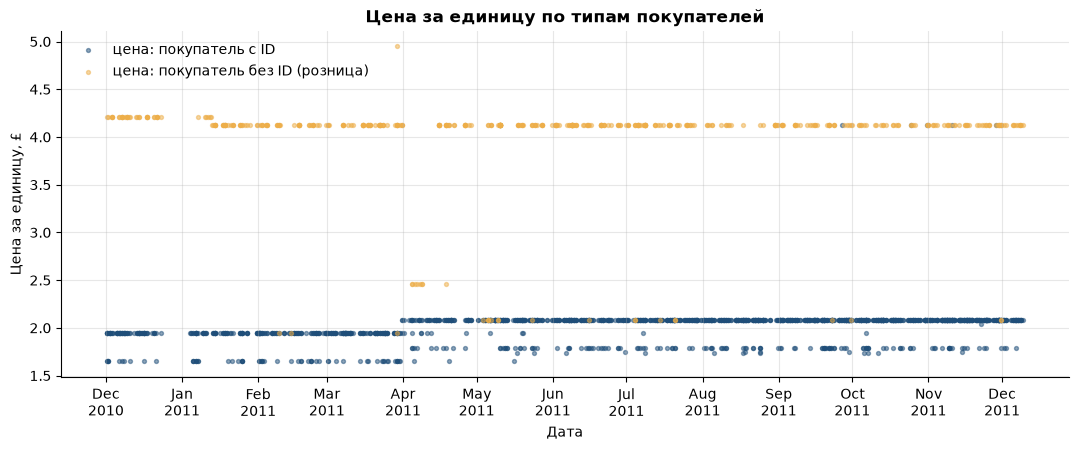

In [5]:
display(rt.price_profile(tx))
fig = rp.plot_price(tx, "Цена за единицу по типам покупателей"); plt.show()

Показатель продаж: **количество проданных единиц (`Quantity`, шт.) за период.**

Выручка хуже подходит для анализа спроса. Оптовые клиенты (с `CustomerID`) платят около £2.08, розничные (без ID) около £4.13, к тому же цены менялись во времени (уровни 1.65 / 1.79 / 1.95 / 2.08). Выручка смешивает изменения объёма с изменениями цены и структуры покупателей, а количество в штуках отражает именно спрос. Покупатели с ID дают ~95% единиц, так что ряд по сути отражает **оптовый спрос**.

### 1.5 Календарь работы магазина

Отсутствие продаж в какой-то день может означать две совершенно разные вещи: магазин работал, но товар не купили (истинный ноль), или магазин не работал (наблюдения нет). Чтобы их различить, календарь рабочих дней восстанавливается по **всем** транзакциям датасета: день считается рабочим, если в нём есть хотя бы одна продажа любого товара.

In [6]:
calendar = rt.StoreCalendar(raw)
display(calendar.summary().to_frame("значение"))
closed = calendar.closed_days
display(closed["weekday"].value_counts().rename("нерабочих дней").to_frame())
display(closed[closed["type"] == "holiday"])

,значение
первая дата,2010-12-01
последняя дата,2011-12-09
календарных дней,374
рабочих дней,305
нерабочих суббот,53
праздничных/каникулярных дней (кроме суббот),16
последняя транзакция,2011-12-09 12:50:00


,нерабочих дней
weekday,
Saturday,53
Monday,6
Friday,4
Sunday,3
Tuesday,1
Wednesday,1
Thursday,1


,weekday,reason,type
Date,,,
2010-12-24,Friday,Сочельник (предпраздничное закрытие),holiday
2010-12-26,Sunday,Рождественские каникулы,holiday
2010-12-27,Monday,Christmas Day (substitute day),holiday
2010-12-28,Tuesday,Boxing Day (substitute day),holiday
2010-12-29,Wednesday,Рождественские каникулы,holiday
2010-12-30,Thursday,Рождественские каникулы,holiday
2010-12-31,Friday,Рождественские каникулы,holiday
2011-01-02,Sunday,Рождественские каникулы,holiday
2011-01-03,Monday,New Year's Day (substitute day),holiday


Магазин **никогда не работает по субботам** (53 из 53 суббот без единой транзакции). Остальные 16 нерабочих дней точно совпадают с государственными праздниками Великобритании и рождественскими каникулами: Good Friday, Easter Monday, Royal Wedding 29.04.2011, May/Spring/Summer Bank Holidays, а также 24.12.2010–03.01.2011. Это закрытия магазина, а не пропуски в данных.

### 1.6 Агрегация по дням, неделям и месяцам

* **День.** Сумма `Quantity` за дату. Рабочий день без продаж → 0, нерабочий → наблюдения нет.
* **Неделя.** `W-SAT`, то есть неделя Вс–Сб, которая совпадает с торговой неделей магазина (Вс–Пт). Так неделя не разрезается посередине.
* **Месяц.** Календарный месяц (`MS`).
* **Неполные периоды** помечаются и исключаются из анализа: первая неделя (данные начинаются в среду 01.12.2010), последняя неделя и **декабрь 2011** (данные обрываются 09.12.2011 в 12:50). Если оставить неполный декабрь, он выглядел бы как обвал продаж.

In [7]:
builder = rt.SalesSeriesBuilder(tx, calendar)
daily_full = builder.daily()          # полный календарь со статусами дней
weekly = builder.weekly()
monthly = builder.monthly()

display(daily_full.head(8))
display(weekly.head(6))
display(monthly)

,value,status,weekday
Date,,,
2010-12-01,556.000,sold,Wednesday
2010-12-02,48.000,sold,Thursday
2010-12-03,49.000,sold,Friday
2010-12-04,NaN,closed,Saturday
2010-12-05,39.000,sold,Sunday
2010-12-06,157.000,sold,Monday
2010-12-07,343.000,sold,Tuesday
2010-12-08,205.000,sold,Wednesday


,value,trading_days,calendar_days_covered,per_trading_day,is_partial
week_end,,,,,
2010-12-04,653.000,3,4,217.667,True
2010-12-11,890.000,6,7,148.333,False
2010-12-18,427.000,6,7,71.167,False
2010-12-25,181.000,5,7,36.200,False
2011-01-01,NaN,0,7,NaN,False
2011-01-08,"1,331.000",4,7,332.750,False


,value,trading_days,calendar_days_covered,per_trading_day,is_partial
month,,,,,
2010-12-01,"2,151.000",20,31,107.550,False
2011-01-01,"2,747.000",24,31,114.458,False
2011-02-01,"3,080.000",24,28,128.333,False
2011-03-01,"5,280.000",27,31,195.556,False
2011-04-01,"2,456.000",21,30,116.952,False
2011-05-01,"3,621.000",25,31,144.840,False
2011-06-01,"3,681.000",26,30,141.577,False
2011-07-01,"3,129.000",26,31,120.346,False
2011-08-01,"5,402.000",26,31,207.769,False


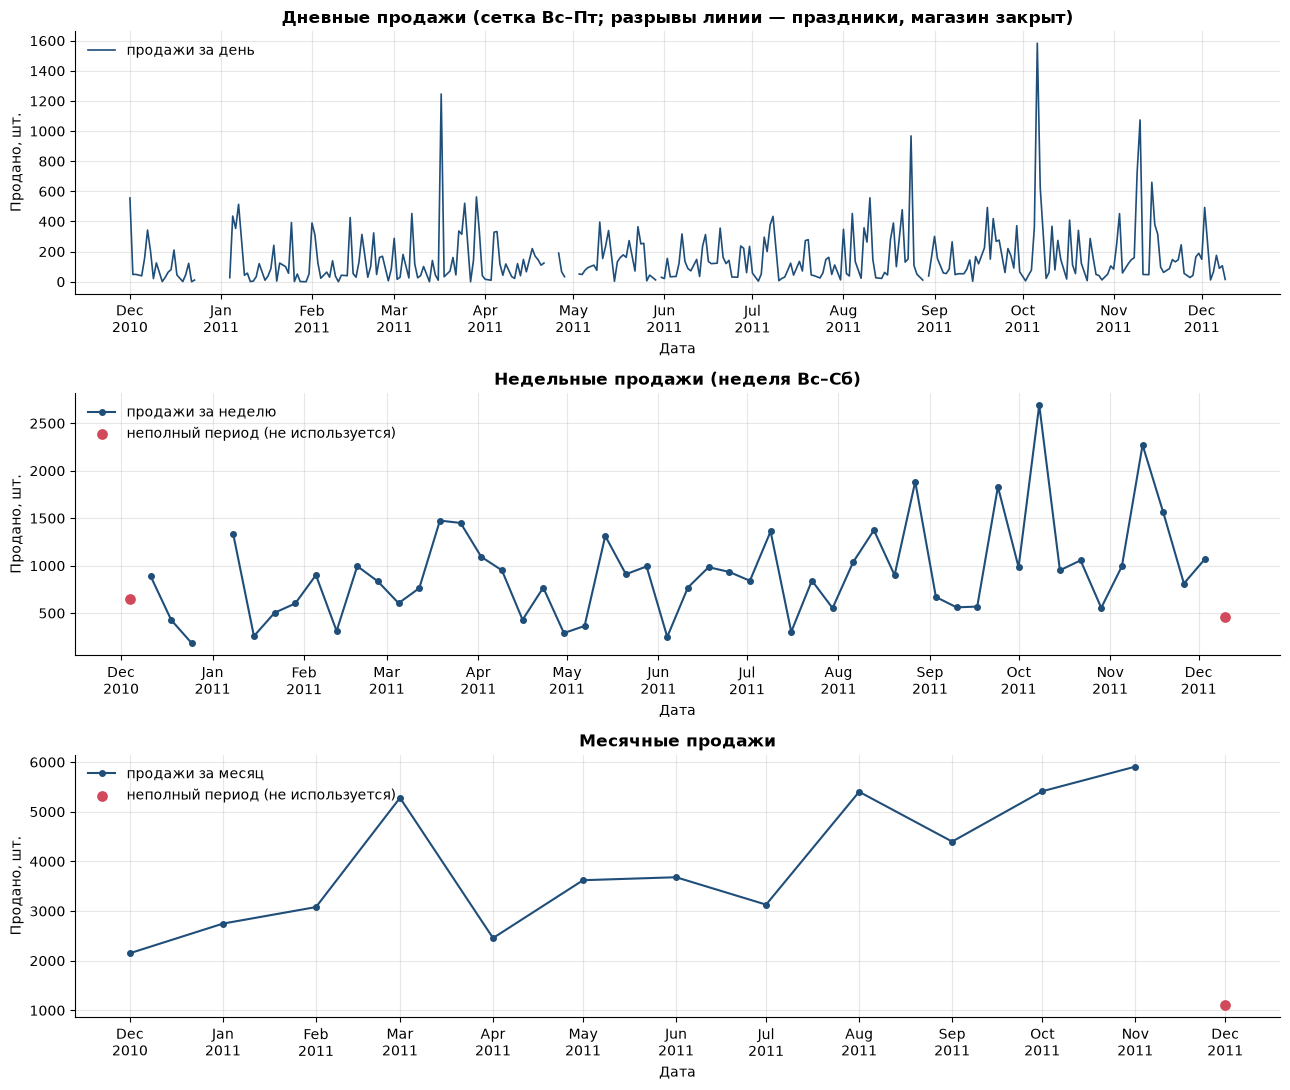

In [8]:
fig = rp.plot_three_frequencies(builder.daily_grid(), weekly, monthly, UNITS); plt.show()

**Календарная корректировка.** В неделях и месяцах разное число рабочих дней: в пасхальной неделе их 3–5 вместо 6, в рождественскую неделю 0, в декабре 2010 только 20 против обычных 26. Сырая сумма за такой период занижает спрос. Поэтому, помимо суммы, строится **ряд с поправкой на число рабочих дней**: продажи за рабочий день × стандартная длина периода (6 дней для недели, 26 для месяца). Рождественская неделя (0 рабочих дней) получает `NaN`, а не 0, потому что спрос в закрытом магазине не наблюдается.

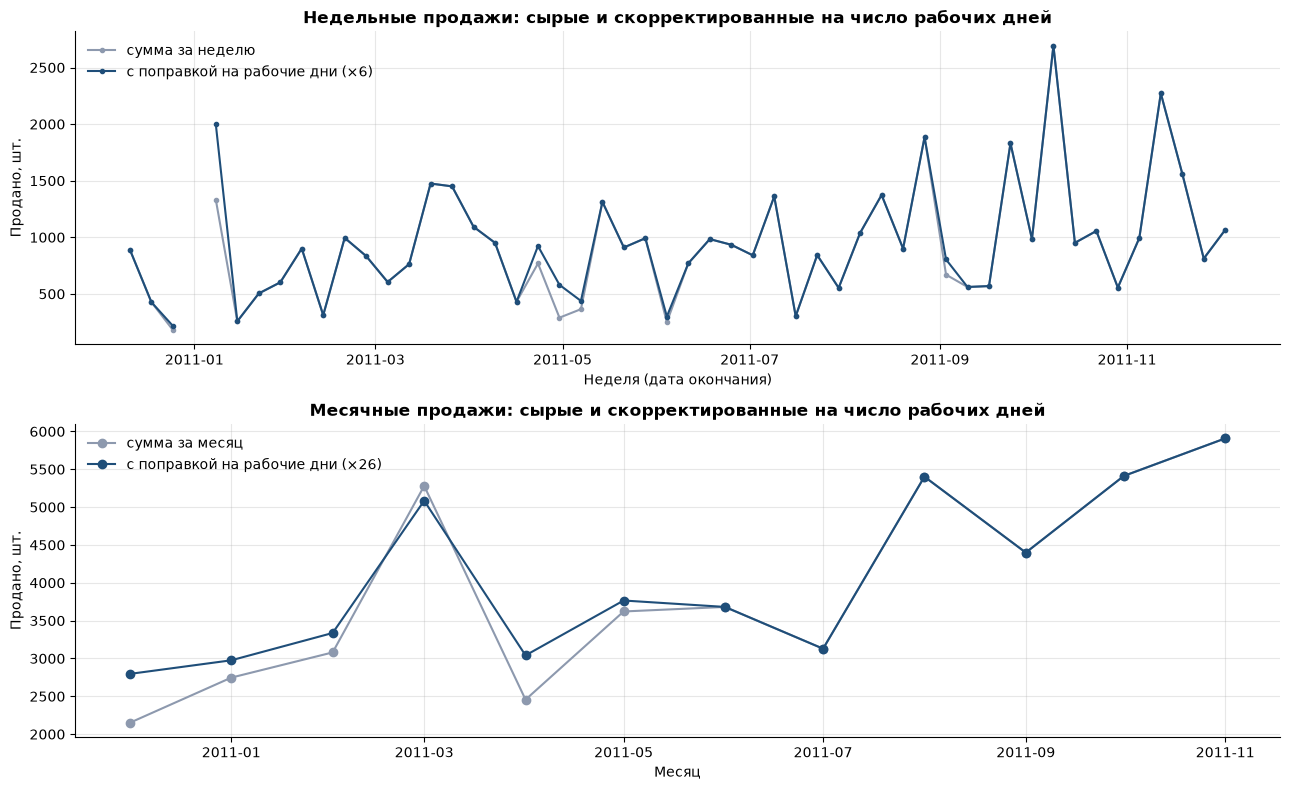

Рабочих дней в неполноценных неделях:


,value,trading_days,per_trading_day
week_end,,,
2010-12-25,181.000,5,36.200
2011-01-01,NaN,0,NaN
2011-01-08,"1,331.000",4,332.750
2011-04-23,769.000,5,153.800
2011-04-30,290.000,3,96.667
2011-05-07,365.000,5,73.000
2011-06-04,250.000,5,50.000
2011-09-03,670.000,5,134.000


In [9]:
w_full = weekly[~weekly["is_partial"]]
m_full = monthly[~monthly["is_partial"]]
weekly_adj = rt.SalesSeriesBuilder.calendar_adjusted(w_full, standard_days=6)
monthly_adj = rt.SalesSeriesBuilder.calendar_adjusted(m_full, standard_days=26)

fig, axes = plt.subplots(2, 1, figsize=(13, 8))
axes[0].plot(w_full.index, w_full["value"], "o-", ms=3, color=rp.COLORS["muted"], label="сумма за неделю")
axes[0].plot(weekly_adj.index, weekly_adj, "o-", ms=3, color=rp.COLORS["main"], label="с поправкой на рабочие дни (×6)")
axes[0].set(title="Недельные продажи: сырые и скорректированные на число рабочих дней", xlabel="Неделя (дата окончания)", ylabel=UNITS)
axes[0].legend(loc="upper left")
axes[1].plot(m_full.index, m_full["value"], "o-", color=rp.COLORS["muted"], label="сумма за месяц")
axes[1].plot(monthly_adj.index, monthly_adj, "o-", color=rp.COLORS["main"], label="с поправкой на рабочие дни (×26)")
axes[1].set(title="Месячные продажи: сырые и скорректированные на число рабочих дней", xlabel="Месяц", ylabel=UNITS)
axes[1].legend(loc="upper left")
fig.tight_layout(); plt.show()

print("Рабочих дней в неполноценных неделях:")
display(w_full.loc[w_full["trading_days"] < 6, ["value", "trading_days", "per_trading_day"]])

**Результат шага 1:** получены три ряда продаж товара в штуках с корректными датами и явной частотой: дневной (на календаре рабочих дней), недельный (Вс–Сб, 52 полные недели) и месячный (12 полных месяцев). Неполные периоды отмечены и исключены, недели и месяцы приведены к сопоставимому числу рабочих дней. Рост во второй половине 2011 года виден во всех трёх частотах.

<a id="step2"></a>
## Шаг 2. Качество данных

### 2.1 Пропуски

Классифицируем каждый календарный день: `sold` (продажи были), `no_sales` (магазин работал, товар не продавался, значит истинный 0), `closed` (магазин закрыт, наблюдения нет). Отдельно ищем дни, где магазин работал, но значение отсутствует: это были бы настоящие пропуски в данных.

In [10]:
missing = rt.MissingDiagnostics(daily_full, calendar.closed_days)
display(missing.status_counts())
print("Рабочих дней с отсутствующим значением (настоящие пропуски данных):", len(missing.unexplained_missing()))
print("\nРабочие дни без продаж товара (истинные нули):")
display(missing.no_sales_days())
print("Серии нерабочих дней длиннее одного дня:")
display(missing.closed_runs())

,дней,"доля, %"
status,,
sold,300,80.210
closed,69,18.450
no_sales,5,1.340


Рабочих дней с отсутствующим значением (настоящие пропуски данных): 0

Рабочие дни без продаж товара (истинные нули):


,value,status,weekday
Date,,,
2010-12-22,0.000,no_sales,Wednesday
2011-01-30,0.000,no_sales,Sunday
2011-02-10,0.000,no_sales,Thursday
2011-03-13,0.000,no_sales,Sunday
2011-03-27,0.000,no_sales,Sunday


Серии нерабочих дней длиннее одного дня:


,start,end,length,reasons
0,2010-12-24 00:00:00,2011-01-03 00:00:00,11,Boxing Day (substitute day); Christmas Day (su...
1,2011-04-22 00:00:00,2011-04-25 00:00:00,4,Easter Monday; Easter Sunday; Good Friday; суб...
2,2011-04-29 00:00:00,2011-04-30 00:00:00,2,Royal Wedding (разовый выходной); суббота (маг...


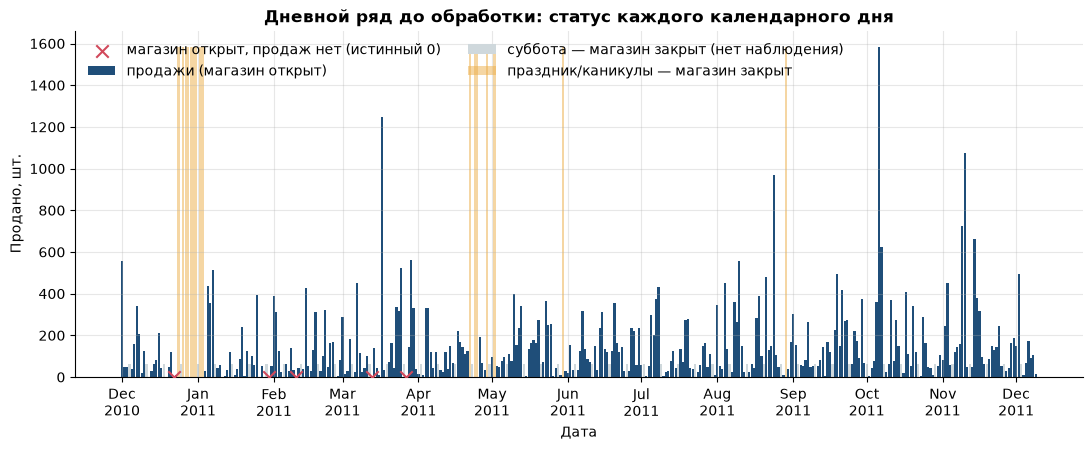

In [11]:
fig = rp.plot_daily_status(daily_full, "Дневной ряд до обработки: статус каждого календарного дня"); plt.show()

In [12]:
print("Пропущенные метки в регулярных сетках:",
      {"неделя W-SAT": missing.calendar_gaps(weekly.index, "W-SAT"), "месяц MS": missing.calendar_gaps(monthly.index, "MS")})
print("Недели без единого рабочего дня (значение = NaN, а не 0):")
display(weekly[weekly["trading_days"] == 0])
print("Пропуски в сырых полях по выбранному товару:")
display(tx[["Description", "CustomerID", "Country", "UnitPrice"]].isna().sum().rename("пропусков").to_frame())

Пропущенные метки в регулярных сетках: {'неделя W-SAT': 0, 'месяц MS': 0}
Недели без единого рабочего дня (значение = NaN, а не 0):


,value,trading_days,calendar_days_covered,per_trading_day,is_partial
week_end,,,,,
2011-01-01,NaN,0,7,NaN,False


Пропуски в сырых полях по выбранному товару:


,пропусков
Description,0
CustomerID,494
Country,0
UnitPrice,0


**Итоги диагностики пропусков:**
* **Настоящих пропусков в данных нет.** Каждый рабочий день магазина имеет значение.
* **5 рабочих дней без продаж** (22.12.2010, 30.01, 10.02, 13.03, 27.03.2011, из них 3 воскресенья, когда продажи и так минимальны). Магазин работал, другие товары продавались, значит это **истинные нули**, и в ряду они остаются нулями.
* **69 нерабочих дней** (53 субботы и 16 праздников) **не заменяются нулями**: в закрытом магазине спрос не наблюдается. Если записать туда 0, получится искусственная сезонность «по субботам продаж нет» и ложные провалы в праздники. Спрос с этих дней переносится на соседние: сразу после рождественских каникул идут очень сильные дни 05.01 и 07.01.2011.
* В недельном ряду есть одна неделя без рабочих дней (26.12.2010–01.01.2011), её значение `NaN`. В месячном ряду пропусков нет. Сетки регулярны (0 пропущенных меток).
* `CustomerID` отсутствует у 494 строк. Это розничные покупки, на показатель «количество» они не влияют.

**Обработка пропусков:**
1. Для описательной статистики используется ряд **только по рабочим дням**, без заполнения.
2. STL, ACF/PACF и тесты стационарности требуют регулярной сетки без разрывов. Для них используется сетка «торговой недели» **Вс–Пт**: субботы исключены систематически, поэтому период 6 сохраняется. 16 праздничных дней на этой сетке **заполняются линейной интерполяцией** и явно отмечаются на графиках. Интерполяция описывает «нормальный уровень спроса», который был бы при открытом магазине, и не создаёт ложных нулей. Таких дней 5% от сетки, и в п. 5.3 проверяется, что выводы не зависят от этой процедуры.
3. Рождественская неделя в недельном ряду заполняется так же, интерполяцией между соседними неделями.

Сетка Вс–Пт: 321 дней, интерполировано праздников: 16
Недельный ряд: 52 недель, интерполировано: [datetime.date(2011, 1, 1)]


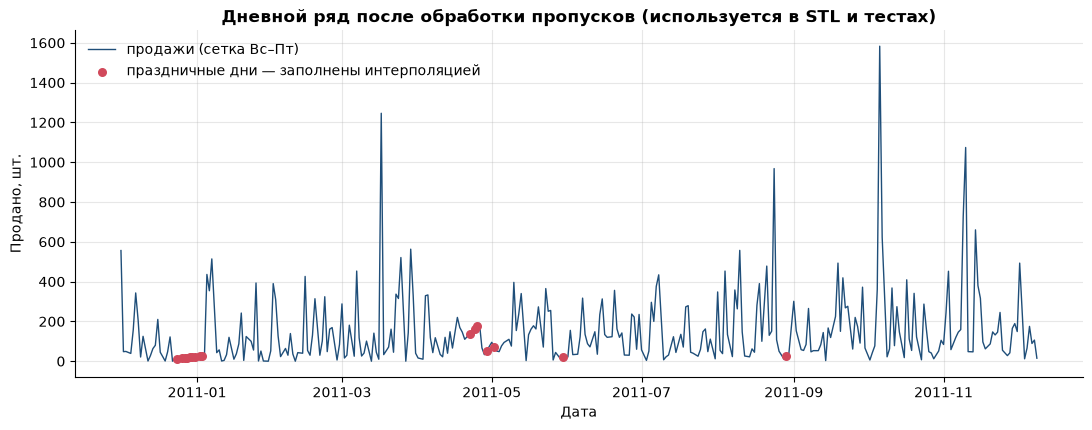

In [13]:
grid_raw = builder.daily_grid()                     # сетка Вс–Пт, праздники = NaN
daily, imputed_days = rt.impute_closed_days(grid_raw)
weekly_a, imputed_weeks = rt.impute_closed_days(weekly_adj)
daily_trading = builder.daily_trading()             # только рабочие дни, без заполнения

print(f"Сетка Вс–Пт: {len(daily)} дней, интерполировано праздников: {len(imputed_days)}")
print(f"Недельный ряд: {len(weekly_a)} недель, интерполировано: {list(imputed_weeks.date)}")

fig, ax = plt.subplots(figsize=(13, 4.5))
ax.plot(daily.index, daily, color=rp.COLORS["main"], lw=1, label="продажи (сетка Вс–Пт)")
ax.scatter(imputed_days, daily[imputed_days], color=rp.COLORS["accent"], zorder=3, s=30,
           label="праздничные дни — заполнены интерполяцией")
ax.set(title="Дневной ряд после обработки пропусков (используется в STL и тестах)", xlabel="Дата", ylabel=UNITS)
ax.legend(loc="upper left"); plt.show()

### 2.2 Выбросы

Распределение дневных продаж сильно скошено вправо, поэтому правило «3σ», которое опирается на нормальность, здесь не подходит. Используем три метода с разными допущениями и смотрим, где они сходятся:

| метод | идея | учитывает тренд | учитывает сезонность |
|---|---|---|---|
| **IQR (Тьюки)** | вне $[Q_1 - 1.5\,IQR,\; Q_3 + 1.5\,IQR]$ | нет | нет |
| **Фильтр Хампеля** | отклонение от скользящей медианы (13 дней) больше $3 \cdot 1.4826 \cdot MAD$ | да | нет |
| **Остатки робастной STL** | робастный z-score остатка STL($\log(1+y)$) больше 3.5 | да | да |

Выбросом считается день, отмеченный **как минимум двумя методами** (консенсус).

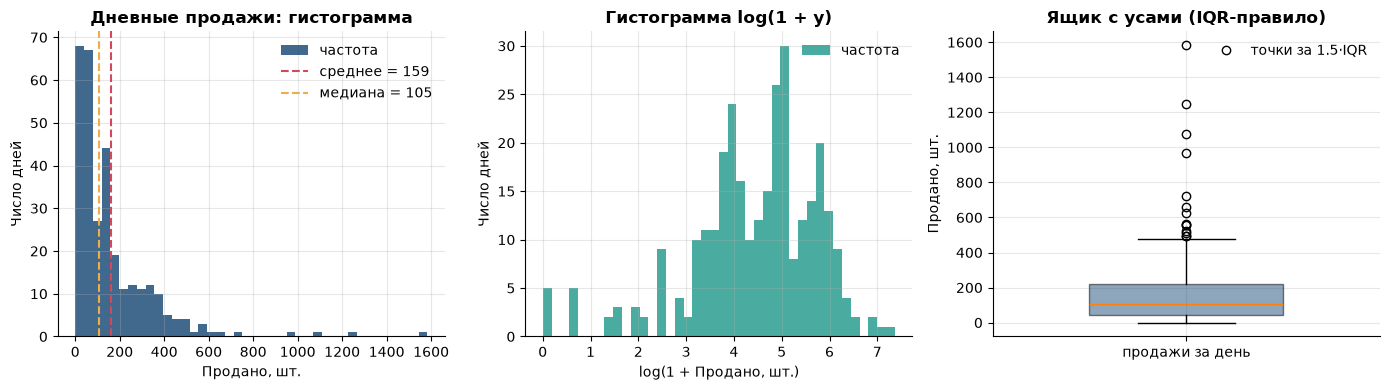

In [14]:
fig = rp.plot_distribution(daily_trading, "Дневные продажи", UNITS); plt.show()

,число выбросов,"доля, %"
IQR,22,6.850
Hampel,31,9.660
STL-resid,25,7.790
консенсус (≥2 методов),18,5.610


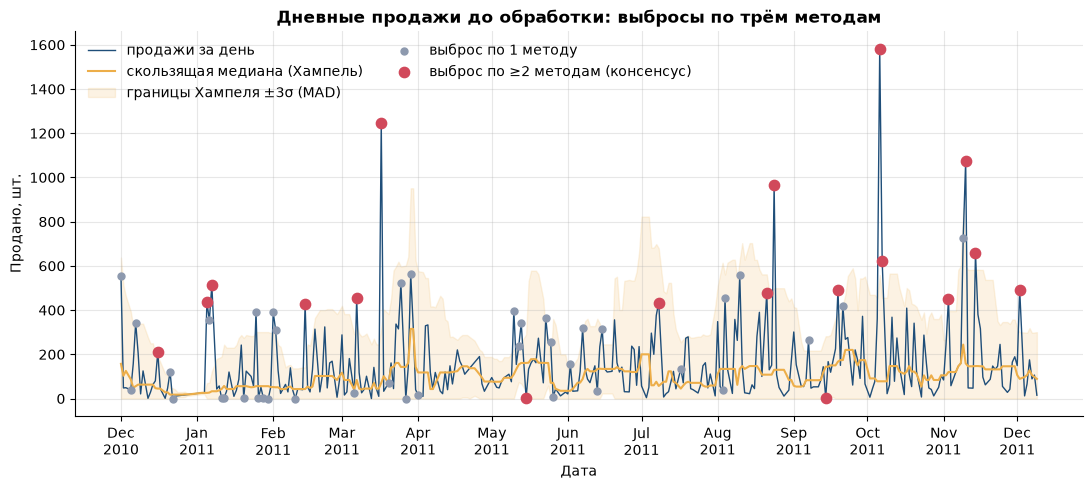

In [15]:
detector = rt.OutlierDetector(period=PERIOD, hampel_window=13, n_sigma=3, iqr_k=1.5, stl_z=3.5, min_votes=2).fit(daily)
display(detector.summary())
fig = rp.plot_outliers(daily, detector.flags_, detector.details_["Hampel"],
                       "Дневные продажи до обработки: выбросы по трём методам", UNITS); plt.show()

In [16]:
outliers = detector.outliers
explained = rt.explain_outliers(outliers.index, tx)
explained["weekday"] = pd.to_datetime(explained["date"]).dt.day_name()
explained["methods"] = outliers[["IQR", "Hampel", "STL-resid"]].apply(lambda r: ", ".join(r.index[r]), axis=1).values
display(explained)

big = tx[tx["Quantity"] >= 300]
print(f"Строк заказа ≥ 300 шт.: {len(big)} ({len(big) / len(tx) * 100:.1f}% строк), "
      f"они дают {big['Quantity'].sum() / tx['Quantity'].sum() * 100:.1f}% всех единиц; "
      f"клиентов: {big['CustomerID'].nunique()}")
display(big.groupby("CustomerID")["Quantity"].agg(["count", "sum"]).sort_values("sum", ascending=False))

,date,units_total,n_lines,largest_order_units,largest_share_%,largest_customer,largest_country,weekday,methods
0,2010-12-16,210,8,100,47.600,"13,093.000",United Kingdom,Thursday,"Hampel, STL-resid"
1,2011-01-05,436,5,200,45.900,"13,629.000",United Kingdom,Wednesday,"IQR, Hampel"
2,2011-01-07,514,4,400,77.800,"15,769.000",United Kingdom,Friday,"IQR, Hampel"
3,2011-02-14,426,4,400,93.900,"15,769.000",United Kingdom,Monday,"IQR, Hampel, STL-resid"
4,2011-03-07,453,12,400,88.300,"15,769.000",United Kingdom,Monday,"IQR, Hampel"
5,2011-03-17,1246,7,1200,96.300,"15,769.000",United Kingdom,Thursday,"IQR, Hampel, STL-resid"
6,2011-05-15,3,1,3,100.000,"17,758.000",United Kingdom,Sunday,"Hampel, STL-resid"
7,2011-07-08,434,17,200,46.100,"16,029.000",United Kingdom,Friday,"IQR, STL-resid"
8,2011-08-21,478,8,200,41.800,"14,566.000",Channel Islands,Sunday,"IQR, STL-resid"
9,2011-08-24,968,9,300,31.000,"15,769.000",United Kingdom,Wednesday,"IQR, Hampel"


Строк заказа ≥ 300 шт.: 19 (0.9% строк), они дают 17.6% всех единиц; клиентов: 8


,count,sum
CustomerID,,
"15,769.000",9,4000
"15,838.000",3,1700
"16,986.000",1,1000
"16,029.000",2,600
"14,680.000",1,300
"16,182.000",1,300
"16,684.000",1,300
"17,511.000",1,300


**Интерпретация выбросов.**
* Консенсус дал **18 дней (5.6%)**: 16 верхних и 2 нижних. В 13 из 16 верхних выбросов **одна строка крупного оптового заказа** даёт 45–96% продаж дня (200–1200 шт.). В остальных трёх (21.08, 24.08, 19.09) в один день совпали несколько заказов по 100–300 шт. Крупные заказы делают несколько постоянных клиентов: `15769` регулярно заказывает по 400 шт. (07.01, 14.02, 07.03, 02.12), один раз 1 200 шт. (17.03), к нему добавляются `15838` и `16986` (по 1 000 шт.). Всего 19 строк ≥ 300 шт. (0.9% строк) от 8 клиентов дают ~18% годового объёма.
* Отдельная группа: **05.01 и 07.01.2011**, отложенный спрос сразу после рождественских каникул.
* Два нижних выброса (15.05 и 14.09.2011, по 3 шт.) лежат в пределах обычных значений (IQR их не отмечает), но аномальны относительно локального уровня.
* **Ошибок данных среди выбросов нет.** Это настоящие продажи с корректными ценами, клиентами и счетами, их источник — крупные заказы, характерные для оптового бизнеса.

**Решение: не удалять и не корректировать выбросы в основном ряду.**
1. Это реальный спрос. Если его удалить, суммарный объём и риск дефицита будут занижены, а модель «научится», что крупных заказов не бывает.
2. Методы дальше устойчивы к ним сами: робастная STL присваивает выбросам малые веса, преобразование Бокса–Кокса сжимает правый хвост, тесты Краскела–Уоллиса и Левене непараметрические.
3. Для **проверки чувствительности** строится вспомогательный ряд, где только консенсусные верхние выбросы ограничены верхней границей Хампеля (winsorizing). Все ключевые выводы ниже проверены и на нём.

Ограничено значений: 14; объём снижен на 9.5%


,mean,median,std,CV (std/mean),max,skewness,excess kurtosis
исходный,153.248,97.000,184.721,1.205,"1,583.000",3.250,16.588
с ограничением выбросов,138.666,95.000,135.629,0.978,725.000,1.432,1.781


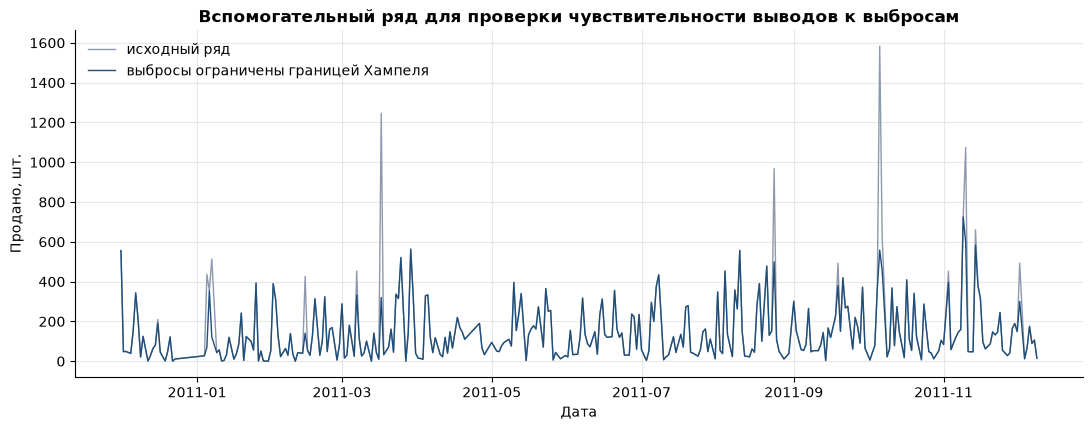

In [17]:
daily_capped = rt.cap_outliers(daily, detector.flags_["consensus"], detector.upper_bound())
print(f"Ограничено значений: {(daily_capped != daily).sum()}; "
      f"объём снижен на {(1 - daily_capped.sum() / daily.sum()) * 100:.1f}%")
display(rt.descriptive_stats({"исходный": daily, "с ограничением выбросов": daily_capped})
        [["mean", "median", "std", "CV (std/mean)", "max", "skewness", "excess kurtosis"]])

fig, ax = plt.subplots(figsize=(13, 4.5))
ax.plot(daily.index, daily, color=rp.COLORS["muted"], lw=1, label="исходный ряд")
ax.plot(daily_capped.index, daily_capped, color=rp.COLORS["main"], lw=1, label="выбросы ограничены границей Хампеля")
ax.set(title="Вспомогательный ряд для проверки чувствительности выводов к выбросам", xlabel="Дата", ylabel=UNITS)
ax.legend(loc="upper left"); plt.show()

Ограничение 14 значений (двух верхних выбросов, которые лежат ниже границы Хампеля, и двух нижних оно не касается) снижает объём на ~9.5%, СКО на ~27% (185 → 136), эксцесс с 16.6 до 1.8. Медиана почти не меняется (97 → 95). Выходит, крупные заказы почти полностью определяют «тяжёлый хвост» распределения, но не типичный уровень продаж. Для прогнозирования это аргумент в пользу робастных функций потерь или раздельного моделирования «регулярного» спроса и редких крупных заказов.

<a id="step3"></a>
## Шаг 3. Визуальный и описательный анализ

### 3.1 Описательные статистики по трём частотам

In [18]:
freq_series = {"День (рабочие дни)": daily_trading,
               "Неделя (с поправкой)": weekly_a,
               "Месяц (с поправкой)": monthly_adj}
display(rt.descriptive_stats(freq_series))
display(rt.intermittency(daily_trading).to_frame("дневной ряд"))

,n,mean,median,std,CV (std/mean),min,Q1,Q3,IQR,max,skewness,excess kurtosis,"zero share, %",sum
День (рабочие дни),305.000,158.593,105.000,187.581,1.183,0.000,43.000,220.000,177.000,"1,583.000",3.195,16.014,1.639,"48,371.000"
Неделя (с поправкой),52.000,957.007,905.500,512.702,0.536,217.200,577.250,"1,072.750",495.500,"2,693.000",1.211,1.748,0.000,"49,764.350"
Месяц (с поправкой),12.000,"4,077.577","3,723.420","1,113.383",0.273,"2,796.300","3,106.940","5,163.833","2,056.893","5,908.000",0.411,-1.388,0.000,"48,930.930"


,дневной ряд
ADI,1.017
CV²,1.360
класс спроса,erratic


* **День.** Средние продажи ~159 шт., медиана 105. Среднее выше медианы, CV ≈ 1.18, асимметрия ≈ 3.2, эксцесс ≈ 16: распределение сильно скошено вправо, с тяжёлым хвостом крупных заказов. Нулей всего 1.6%.
* **Классификация Syntetos–Boylan:** ADI ≈ 1.02 (продажи почти каждый день), CV² ≈ 1.36 > 0.49, то есть спрос **erratic** (регулярный, но с очень большим разбросом объёмов). Методы для прерывистого спроса (Croston) здесь не нужны, зато важна робастность к большим значениям.
* **Неделя и месяц.** При агрегации CV падает до ~0.54 и ~0.27, а асимметрия заметно снижается, потому что крупные заказы усредняются. Агрегированные ряды намного «спокойнее», но и наблюдений в них меньше (52 и 12).

### 3.2 Структура продаж: размер заказов, клиенты, страны

,строк,единиц,"доля строк, %","доля единиц, %"
Quantity,,,,
"(0.0, 10.0]",1577,9568,74.775,19.780
"(10.0, 50.0]",320,7338,15.173,15.170
"(50.0, 100.0]",152,14934,7.207,30.874
"(100.0, 500.0]",57,13331,2.703,27.560
"(500.0, inf]",3,3200,0.142,6.616


,значение
уникальных (CustomerID),635.000
"доля top-1, %",10.006
"доля top-10, %",39.414
уникальных (Country),20.000
"доля top-1, %",91.296
"доля top-3, %",96.510


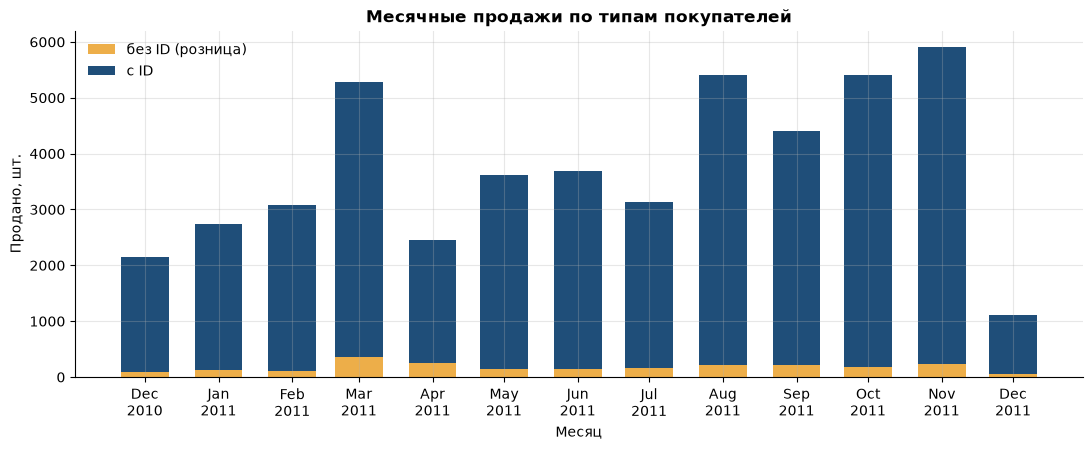

In [19]:
display(rt.order_size_distribution(tx))
display(pd.concat([rt.concentration(tx, "CustomerID", top=10), rt.concentration(tx, "Country", top=3)]).to_frame("значение"))
fig = rp.plot_customer_mix(tx, "Месячные продажи по типам покупателей"); plt.show()

* **75% строк** заказа содержат до 10 шт., но дают лишь ~20% объёма. Строки больше 50 шт. (10% строк) дают **~65% объёма**. Объём продаж определяется небольшим числом крупных заказов, отсюда и высокая волатильность ряда.
* Концентрация по клиентам: из 635 клиентов на top-1 приходится 10% объёма, на top-10 ~39%. По странам на Великобританию приходится 91%.
* Доля розничных покупателей без ID мала (~5%) и стабильна, поэтому динамику ряда определяют оптовые клиенты.

### 3.3 Изменение уровня и разброса во времени

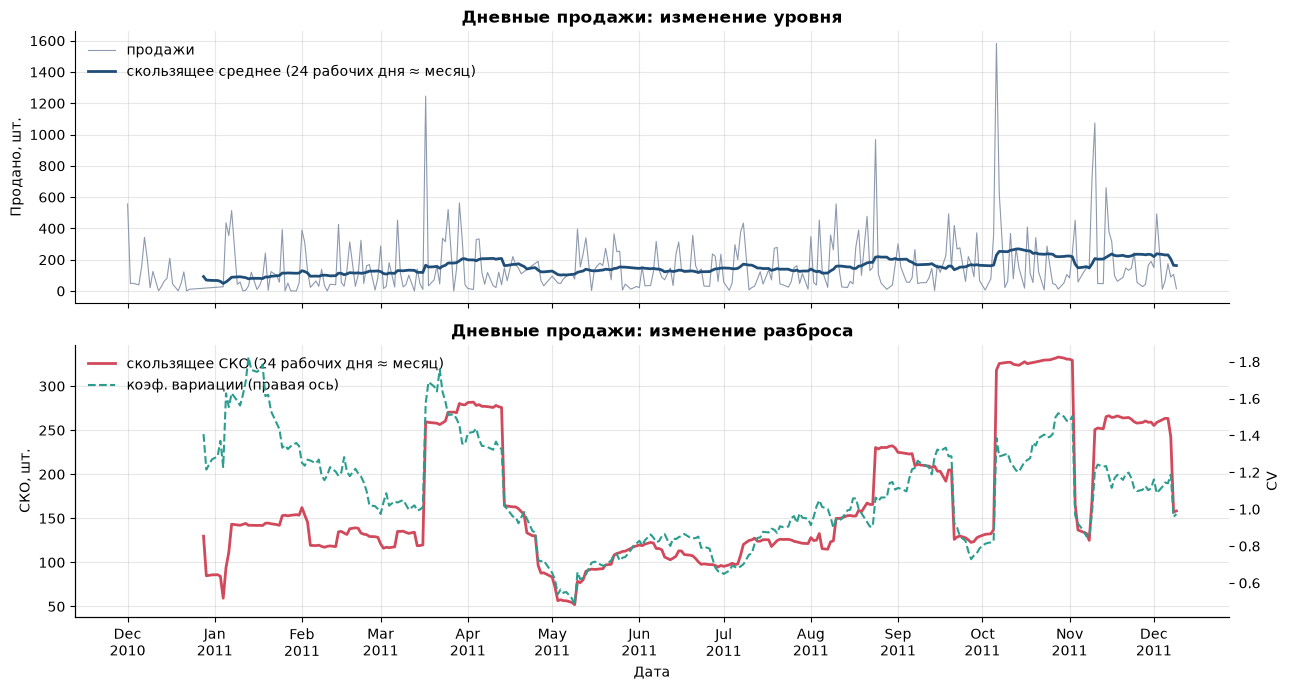

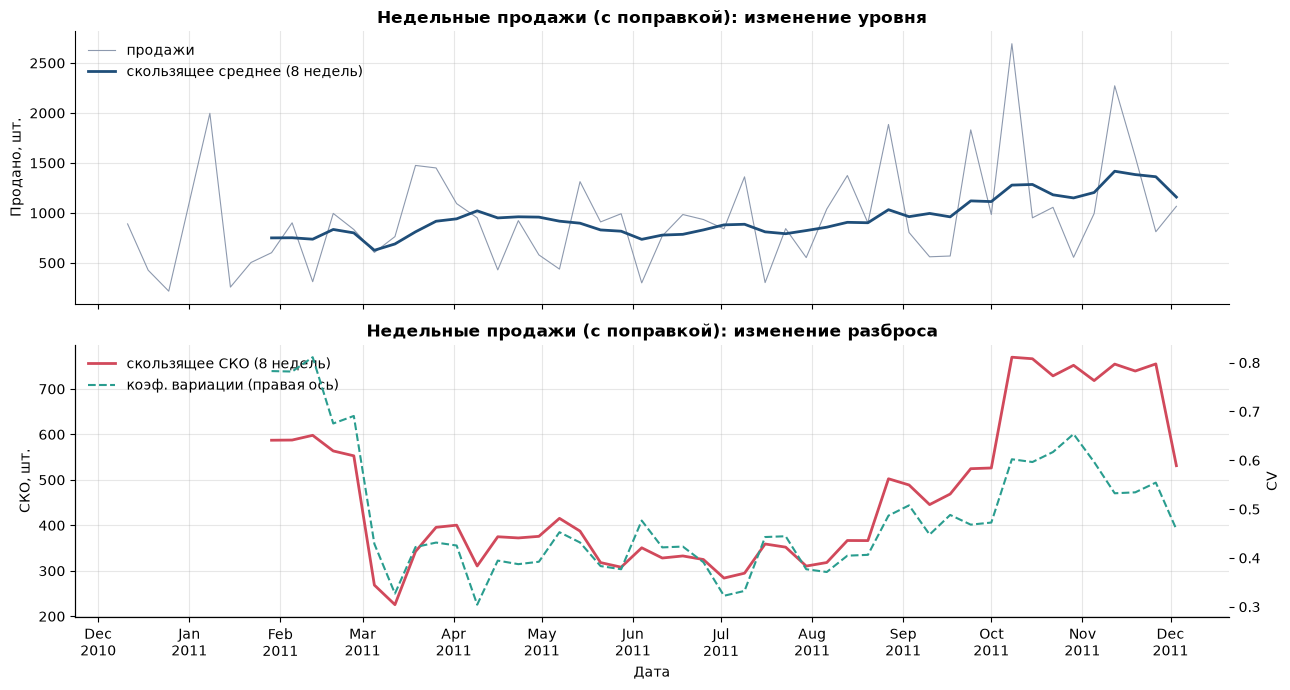

In [20]:
roll_d = rt.rolling_stats(daily, window=24)   # 24 рабочих дня ≈ 4 недели
fig = rp.plot_rolling(roll_d, "Дневные продажи", UNITS, "24 рабочих дня ≈ месяц"); plt.show()
roll_w = rt.rolling_stats(weekly_a, window=8)
fig = rp.plot_rolling(roll_w, "Недельные продажи (с поправкой)", UNITS, "8 недель"); plt.show()

,mean,median,std,n,cv
Date,,,,,
2010-12-01,107.550,48.500,137.440,20,1.278
2011-01-01,114.458,51.500,153.568,24,1.342
2011-02-01,128.333,74.000,128.470,24,1.001
2011-03-01,195.556,101.000,267.310,27,1.367
2011-04-01,116.952,118.000,93.080,21,0.796
2011-05-01,144.840,110.000,115.422,25,0.797
2011-06-01,141.577,128.500,95.797,26,0.677
2011-07-01,120.346,65.000,119.544,26,0.993
2011-08-01,207.769,132.000,223.866,26,1.077


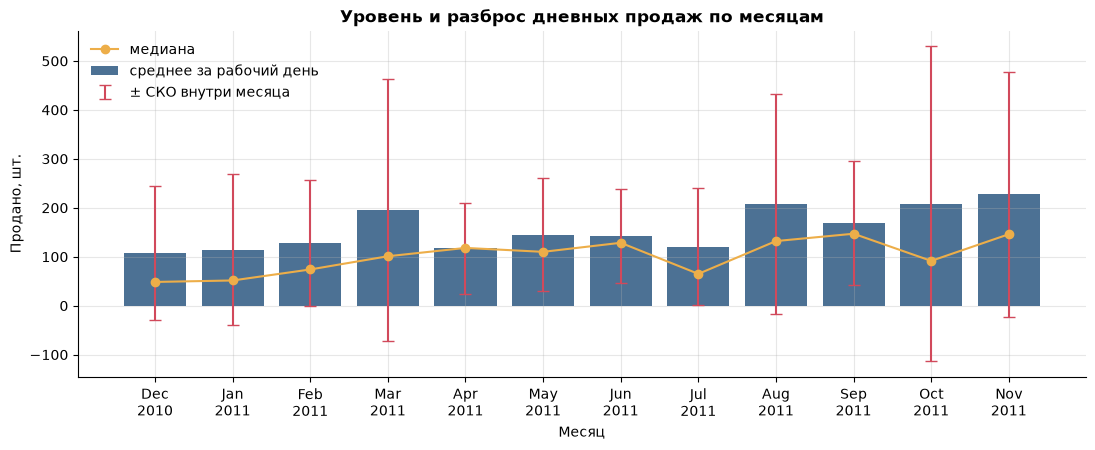

In [21]:
by_month = rt.level_spread_by_period(daily_trading, "MS").iloc[:-1]   # без неполного декабря 2011
display(by_month)
fig = rp.plot_monthly_profile(by_month, "Уровень и разброс дневных продаж по месяцам", UNITS); plt.show()

,значение
"Spearman rho(mean, std)",0.552
p-value,0.063
наклон log std ~ log mean,1.227
λ ≈ 1 − наклон,-0.227
робастный наклон log IQR ~ log median,0.534
λ ≈ 1 − робастный наклон,0.466


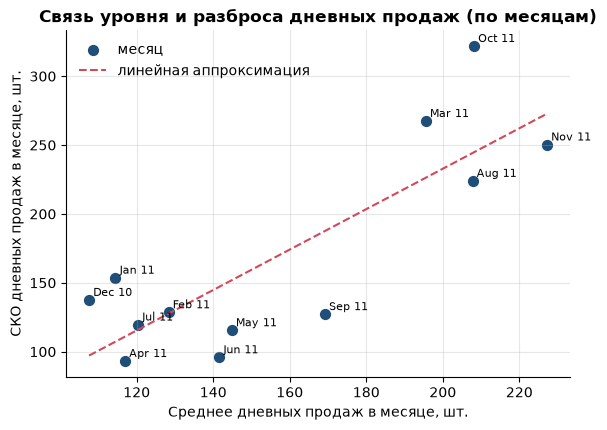

,"сырой ряд, по кварталам"
Levene (median) stat,1.959
Levene p-value,0.101
Fligner stat,6.861
Fligner p-value,0.143
число групп,5.000


In [22]:
display(rt.mean_variance_relation(daily_trading.loc[:"2011-11-30"], "MS").to_frame("значение"))
fig = rp.plot_level_vs_spread(by_month, "Связь уровня и разброса дневных продаж (по месяцам)"); plt.show()
display(rt.variance_homogeneity(daily_trading, "QS").to_frame("сырой ряд, по кварталам"))

**Уровень.** Скользящее среднее растёт: ~110 шт./день в декабре–феврале, ~140 летом и ~210–230 в августе–ноябре 2011 года. На фоне общего роста видны всплески (март, август), которые совпадают с крупными заказами.

**Разброс.** Скользящее СКО двигается вместе с уровнем: месяцы с высоким средним (март, август, октябрь, ноябрь) имеют и высокое СКО. Корреляция Спирмена месячного среднего и СКО ρ ≈ 0.55, а по сетке Вс–Пт ниже ρ ≈ 0.65 (p ≈ 0.02). **Разброс зависит от уровня**, значит, перед декомпозицией и тестами нужно преобразование, стабилизирующее дисперсию. Его выбор:
* Наклон $\log\sigma$ на $\log\mu$ ≈ 1.2 формально указывает на логарифм (λ ≈ −0.2). Но σ и μ сильно завышены в месяцах с крупными заказами, поэтому оценка смещена. **Робастный** наклон $\log IQR$ на $\log(\text{медиана})$ ≈ 0.53 даёт λ ≈ 0.47.
* Поэтому λ выбирается методом Герреро, в классическом и в робастном варианте, и на кандидатах проверяется, исчезла ли зависимость «разброс ~ уровень».

### 3.3.1 Выбор преобразования, стабилизирующего дисперсию (Бокс–Кокс)

Герреро (std/mean):          λ = 0.02
Герреро робастный (IQR/med): λ = 0.33


,λ,"ρ(среднее, СКО) по месяцам",p-value ρ,Levene p (4 отрезка),Levene p (кварталы),СКО по отрезкам
без преобразования (λ=1),1.000,0.648,0.017,0.164,0.042,"133.01, 176.29, 158.03, 244.69"
λ=0.50,0.500,0.330,0.271,0.729,0.049,"11.57, 11.82, 11.22, 13.75"
λ=0.33,0.330,0.038,0.901,0.882,0.035,"5.48, 5.20, 4.85, 5.61"
λ=0.25,0.250,-0.203,0.505,0.721,0.022,"3.94, 3.61, 3.31, 3.75"
log1p (λ=0),0.000,-0.731,0.005,0.039,0.001,"1.58, 1.29, 1.06, 1.15"


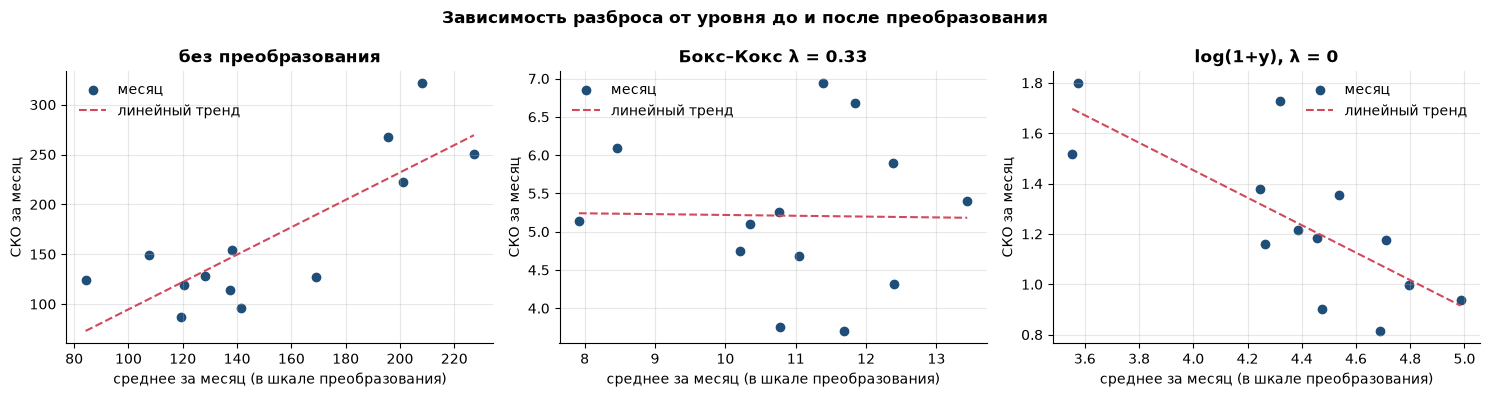

In [23]:
lam_guerrero = rt.guerrero_lambda(daily, block=24)                 # блоки по 24 рабочих дня ≈ месяц
lam_guerrero_robust = rt.guerrero_lambda(daily, block=24, robust=True)
print(f"Герреро (std/mean):          λ = {lam_guerrero:.2f}")
print(f"Герреро робастный (IQR/med): λ = {lam_guerrero_robust:.2f}")

LAM = round(lam_guerrero_robust, 2)
vst = rt.variance_stabilization_table(daily, [None, 0.5, LAM, 0.25, 0.0])
display(vst)

fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, (lam, name) in zip(axes, [(None, "без преобразования"), (LAM, f"Бокс–Кокс λ = {LAM}"), (0.0, "log(1+y), λ = 0")]):
    x = daily if lam is None else rt.boxcox1p(daily, lam)
    g = x.groupby(pd.Grouper(freq="MS"))
    ax.scatter(g.mean(), g.std(), color=rp.COLORS["main"], label="месяц")
    k = np.polyfit(g.mean(), g.std(), 1)
    xs = np.linspace(g.mean().min(), g.mean().max(), 10)
    ax.plot(xs, np.polyval(k, xs), "--", color=rp.COLORS["accent"], label="линейный тренд")
    ax.set(title=name, xlabel="среднее за месяц (в шкале преобразования)", ylabel="СКО за месяц")
    ax.legend()
fig.suptitle("Зависимость разброса от уровня до и после преобразования", fontweight="bold")
fig.tight_layout(); plt.show()
BC = lambda x: rt.boxcox1p(x, LAM)      # выбранное преобразование, используется далее

* **Классический Герреро даёт λ ≈ 0 (логарифм).** Но это та же проблема, что и с наклоном: в месяцах с крупными заказами СКО завышено выбросами. Робастный вариант (IQR/медиана) даёт **λ ≈ 0.33**.
* Таблица кандидатов показывает, что сильнее всего зависимость разброса от уровня убирает **λ = 0.33**: ρ(среднее, СКО) ≈ 0.04 (p ≈ 0.9), СКО по четырём отрезкам ряда почти одинаково (Левене p ≈ 0.88).
  * Без преобразования ρ ≈ 0.65: разброс растёт с уровнем.
  * **Логарифм перекорректирует**: ρ ≈ −0.73 (p ≈ 0.005). В лог-шкале разброс *уменьшается* с ростом уровня, потому что log сильно растягивает малые значения (воскресенья, почти нулевые зимние дни), и Левене отвергает равенство дисперсий (p ≈ 0.04 и 0.001).
  * λ = 0.5 (корень) недокорректирует (ρ ≈ 0.33).
* По кварталам Левене даже при λ = 0.33 на границе значимости (p ≈ 0.035), но это лучший результат среди кандидатов, а оставшаяся разница связана с трендом уровня и снимается вместе с ним (п. 5.4).

**Выбрано: преобразование Бокса–Кокса для $1+y$ с λ = 0.33** (≈ кубический корень): $\;\tilde y = \frac{(1+y)^{\lambda} - 1}{\lambda}$. Сдвиг «+1» нужен из-за 5 нулевых дней. Дальше это преобразование обозначается `BC`. Логарифм остаётся для сравнения.

### 3.4 Внутринедельный профиль

,mean,median,std,n,index (mean / overall mean)
weekday,,,,,
Sunday,56.660,30.000,80.582,50,0.357
Monday,164.617,105.000,152.007,47,1.038
Tuesday,178.404,150.500,125.212,52,1.125
Wednesday,189.491,135.000,194.567,53,1.195
Thursday,219.113,134.000,298.777,53,1.382
Friday,137.360,83.000,149.613,50,0.866


,Краскел–Уоллис по дням недели
H,47.161
p-value,0.000
число групп,6.000
epsilon² (размер эффекта),0.141


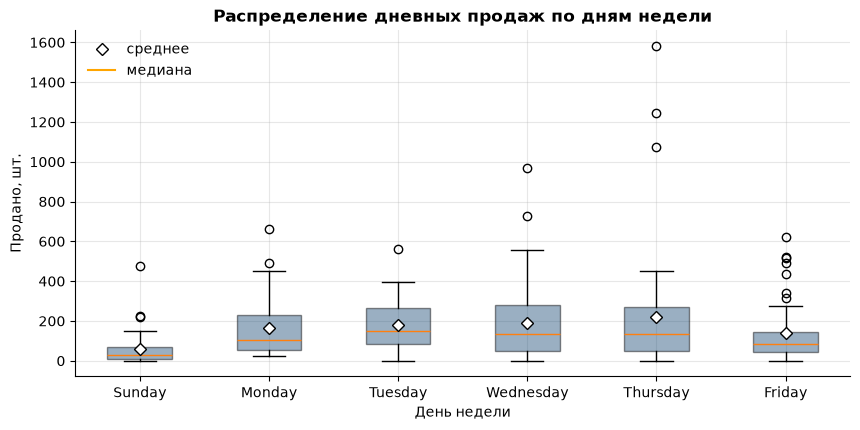

In [24]:
display(rt.weekday_profile(daily_trading))
display(rt.kruskal_by_group(daily_trading, daily_trading.index.day_name()).to_frame("Краскел–Уоллис по дням недели"))
fig = rp.plot_weekday(daily_trading, "Распределение дневных продаж по дням недели", UNITS); plt.show()

Внутринедельный профиль выражен очень чётко. **Воскресенье** — самый слабый день: медиана 30 шт., индекс 0.36 от среднего, в этот день почти нет оптовых заказов. **Вторник–четверг** самые сильные (медиана 134–150), пятница ниже среднего. Критерий Краскела–Уоллиса (H0: распределения продаж одинаковы во все дни недели) уверенно отвергает H0: p ≈ 5·10⁻⁹, размер эффекта ε² ≈ 0.14. Это первый аргумент в пользу недельной сезонности, формально она проверяется в шаге 4.

### 3.5 Автокорреляция и тренд

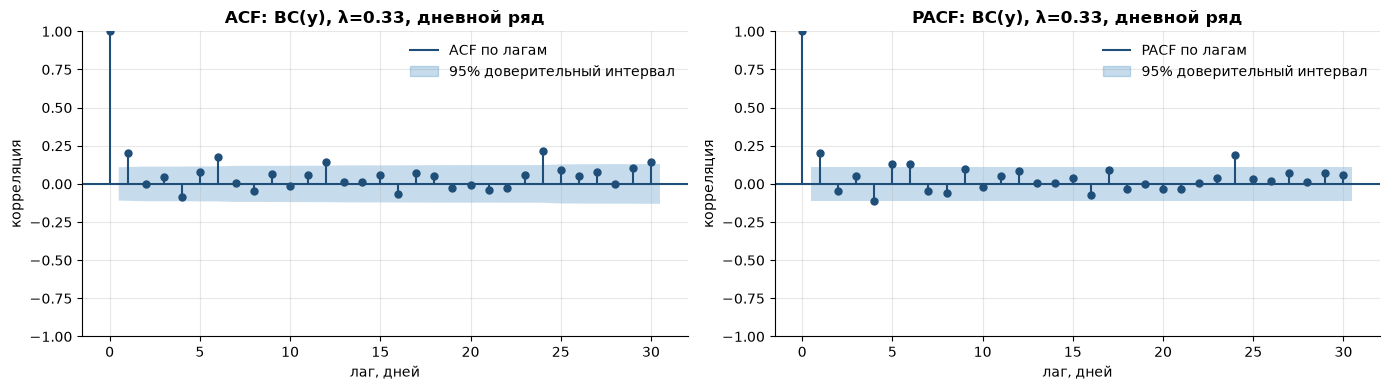

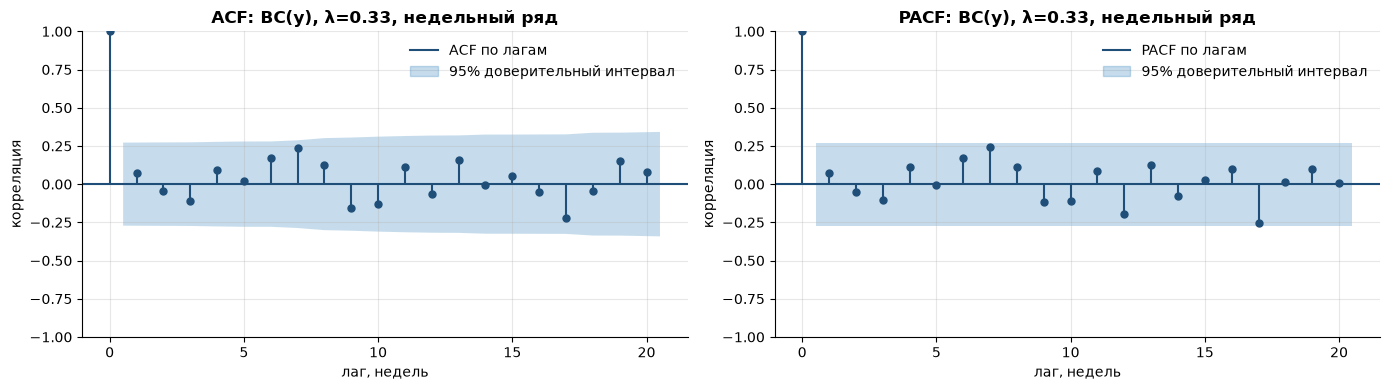

In [25]:
fig = rp.plot_acf_pacf(BC(daily), lags=30, title=f"BC(y), λ={LAM}, дневной ряд"); plt.show()
fig = rp.plot_acf_pacf(BC(weekly_a), lags=20, title=f"BC(y), λ={LAM}, недельный ряд", unit="лаг, недель"); plt.show()

In [26]:
mk = pd.DataFrame({
    "День": rt.mann_kendall(daily),
    "Неделя (с поправкой)": rt.mann_kendall(weekly_a),
    "Месяц (с поправкой)": rt.mann_kendall(monthly_adj),
}).T
display(mk)

,n,Kendall tau,p-value,наклон Сена (за шаг),"наклон, % от среднего за шаг"
День,321.000,0.154,0.000,0.193,0.126
Неделя (с поправкой),52.000,0.220,0.021,8.694,0.908
Месяц (с поправкой),12.000,0.667,0.002,249.375,6.116


* **ACF дневного ряда** значима на лаге 1 (≈ 0.2) и на лагах, **кратных 6** (6 ≈ 0.18, 24 ≈ 0.22; 12 и 30 у границы), а между ними близка к нулю. «Зубцы» с шагом 6 говорят о недельной сезонности. **Медленного линейного затухания, характерного для единичного корня, нет**, и это согласуется с тестами в шаге 5. PACF значима на лагах 1, 4–6 и 24.
* **ACF недельного ряда** почти не выходит за доверительные границы. Устойчивой внутригодовой периодичности на недельной частоте нет, а недельный цикл при агрегации по неделям исчезает по построению.
* **Тренд.** Тест Манна–Кендалла (H0: монотонного тренда нет; τ Кендалла не зависит от монотонного преобразования, поэтому применяется к исходным значениям) отвергает H0 на всех трёх частотах: день τ ≈ 0.15, p < 0.001; неделя τ ≈ 0.22, p ≈ 0.02; месяц τ ≈ 0.67, p ≈ 0.002. Наклон Сена для месячного ряда около +250 шт., или ~6% от среднего, в месяц. **Восходящий тренд статистически значим.**

<a id="step4"></a>
## Шаг 4. Декомпозиция и сезонность

### 4.1 Какие сезонности вообще можно идентифицировать

Сезонность периода $m$ можно надёжно выделить только при наблюдении хотя бы **двух полных циклов** ($n \ge 2m$). STL и классическая декомпозиция формально требуют того же.

In [27]:
ident = pd.DataFrame([
    {"частота": "день (сетка Вс–Пт)", "кандидат": "недельная", "период m": PERIOD, "n": len(daily)},
    {"частота": "день (сетка Вс–Пт)", "кандидат": "годовая", "период m": 6 * 52, "n": len(daily)},
    {"частота": "неделя", "кандидат": "годовая", "период m": 52, "n": len(weekly_a)},
    {"частота": "месяц", "кандидат": "годовая", "период m": 12, "n": len(monthly_adj)},
])
ident["нужно n ≥ 2m"] = ident["период m"] * 2
ident["идентифицируема"] = [rt.seasonality_identifiable(n, m) for n, m in zip(ident["n"], ident["период m"])]
display(ident)

,частота,кандидат,период m,n,нужно n ≥ 2m,идентифицируема
0,день (сетка Вс–Пт),недельная,6,321,12,True
1,день (сетка Вс–Пт),годовая,312,321,624,False
2,неделя,годовая,52,52,104,False
3,месяц,годовая,12,12,24,False


* **Недельная сезонность (m = 6) на дневном ряду** идентифицируема с запасом: ~53 цикла.
* **Годовая сезонность** (m = 52 недели / 12 месяцев) **не идентифицируема**, так как в данных ровно один год. Подъём в сентябре–ноябре согласуется с предрождественским сезоном оптовых закупок, но по одному году его нельзя отделить от тренда: это мог быть и разовый рост бизнеса. **Утверждать наличие годовой сезонности по этим данным нельзя.** Для этого нужно хотя бы 2 года (24 месяца / 104 недели).

### 4.2 Выбор метода декомпозиции

Выбран **STL** (Seasonal-Trend decomposition using LOESS) со следующими настройками:
* **робастный режим**, потому что выбросы от крупных заказов получают малые веса и не искажают тренд и сезонность. Классическая декомпозиция скользящим средним к выбросам чувствительна;
* **на BC(y), λ = 0.33**, то есть в шкале, где разброс не зависит от уровня (п. 3.3.1). В исходной шкале сезонные колебания были бы больше при высоком уровне. В шкале BC модель аддитивна: $BC(y_t) = T_t + S_t + R_t$;
* **period = 6** по сетке Вс–Пт;
* `trend = 49` (≈ 8 недель): тренд описывает изменение уровня на горизонте 1–2 месяцев. При окне по умолчанию (~2 недели) «тренд» начинает повторять случайные колебания от крупных заказов;
* `seasonal = 13`: профиль каждого дня недели сглаживается по ~13 неделям, то есть сезонность может медленно меняться в течение года (в отличие от классической декомпозиции, где она фиксирована), но не подстраивается под шум.

Устойчивость результата к этим настройкам проверена отдельно ниже.

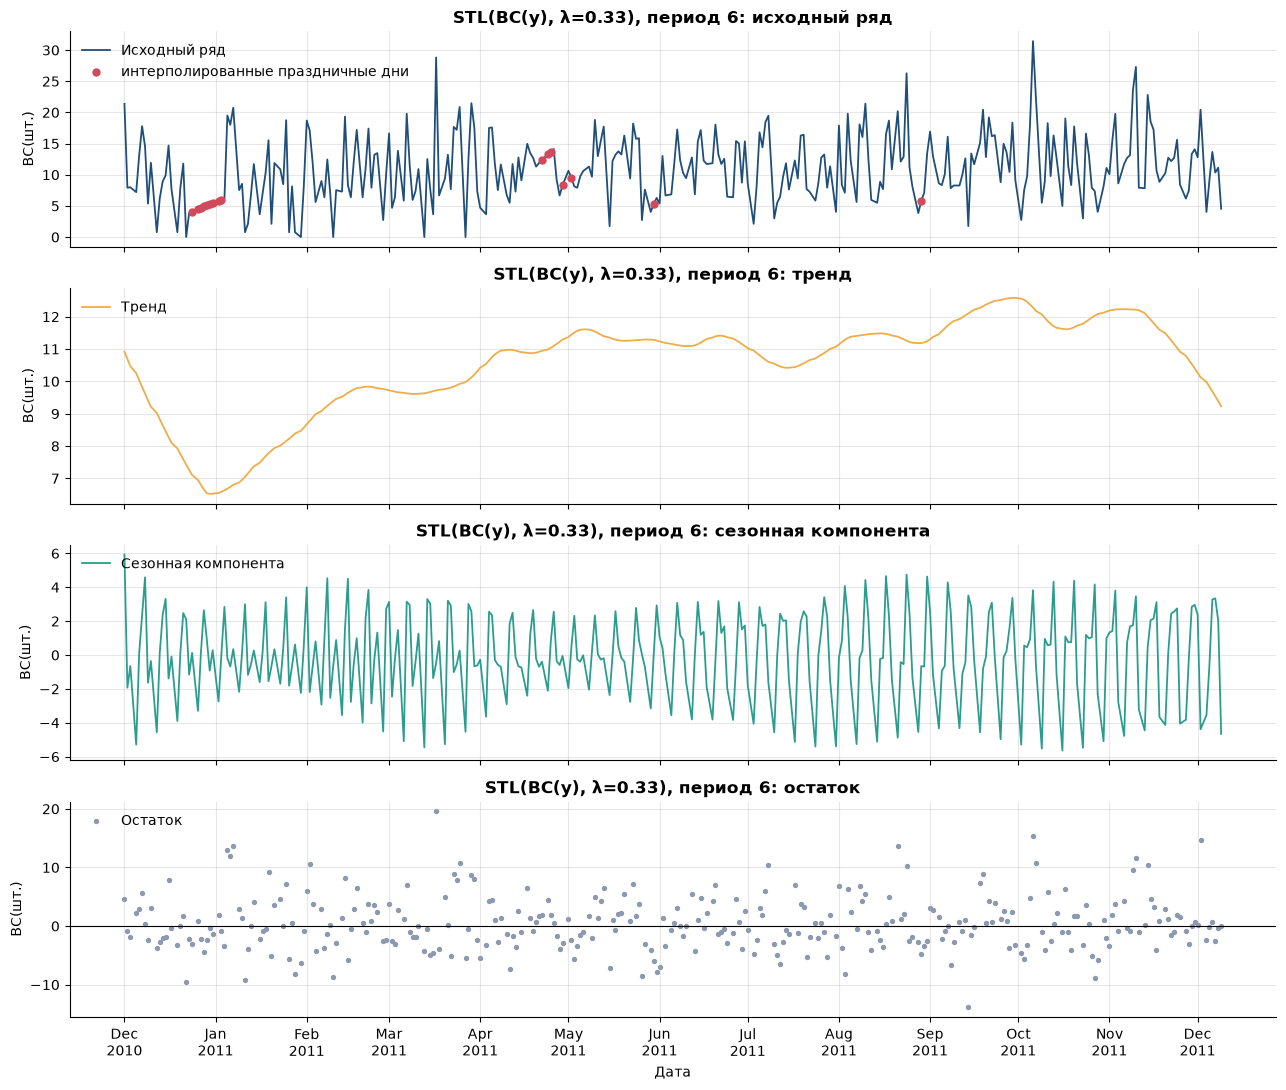

,"STL на BC(y), λ=0.33"
сила тренда F_T,0.096
сила сезонности F_S,0.215


In [28]:
STL_KW = dict(trend=49, seasonal=13)
stl = rt.STLDecomposer(period=PERIOD, lam=LAM, robust=True, **STL_KW).fit(daily)
fig = rp.plot_decomposition(stl.result_, f"STL(BC(y), λ={LAM}), период 6", "BC(шт.)", imputed=imputed_days); plt.show()
display(stl.strength().to_frame(f"STL на BC(y), λ={LAM}"))

In [29]:
def _strength(df):
    return pd.Series({"сила тренда F_T": max(0, 1 - df["resid"].var() / (df["trend"] + df["resid"]).var()),
                      "сила сезонности F_S": max(0, 1 - df["resid"].var() / (df["seasonal"] + df["resid"]).var())})

cmp_rows = {
    f"STL робастная, BC(y) λ={LAM}": stl.strength(),
    "STL робастная, log(1+y)": rt.STLDecomposer(PERIOD, lam=0.0, **STL_KW).fit(daily).strength(),
    "STL робастная, исходный ряд (аддитивная)": rt.STLDecomposer(PERIOD, **STL_KW).fit(daily).strength(),
    f"классическая (скольз. среднее), BC(y)": _strength(rt.classical_decomposition(BC(daily), PERIOD)),
}
display(pd.DataFrame(cmp_rows).T)

# Чувствительность к параметрам STL: сила сезонности и сезонный индекс
sens_rows = {}
for tr in (None, 25, 49, 73):
    for se in (7, 13, 25):
        d = rt.STLDecomposer(PERIOD, lam=LAM, trend=tr, seasonal=se).fit(daily)
        idx = d.seasonal_index()
        sens_rows[(tr or "по умолч.", se)] = {**d.strength().to_dict(), "индекс Вс": idx["Sunday"], "индекс Вт": idx["Tuesday"]}
display(pd.DataFrame(sens_rows).T.rename_axis(["trend", "seasonal"]))

,сила тренда F_T,сила сезонности F_S
"STL робастная, BC(y) λ=0.33",0.096,0.215
"STL робастная, log(1+y)",0.093,0.194
"STL робастная, исходный ряд (аддитивная)",0.028,0.121
"классическая (скольз. среднее), BC(y)",0.305,0.176


сила тренда F_T  сила сезонности F_S  индекс Вс  индекс Вт
trend     seasonal                                                            
по умолч. 7                   0.181                0.284      0.381      1.567
          13                  0.232                0.215      0.376      1.614
          25                  0.275                0.212      0.376      1.547
25        7                   0.136                0.312      0.342      1.544
          13                  0.140                0.216      0.356      1.572
          25                  0.143                0.190      0.354      1.556
49        7                   0.101                0.302      0.341      1.581
          13                  0.096                0.215      0.348      1.557
          25                  0.095                0.186      0.349      1.545
73        7                   0.089                0.323      0.336      1.550
          13                  0.079                0.218      0.346      1.516
          25                  0.075                0.183      0.350      1.532

**Интерпретация компонент.**
* **Тренд.** Провал в конце декабря 2010 – начале января (каникулы), рост с февраля по апрель, плато с мая по август, рост в сентябре–октябре до максимума за год, плато в ноябре. Снижение в декабре 2011 частично краевое: данные обрываются 9 декабря, и у LOESS на краю меньше опоры. В целом тренд восходящий, что согласуется с тестом Манна–Кендалла и скользящими средними из шага 3.
* **Сезонная компонента.** Регулярный 6-дневный «зубец», амплитуда которого почти не меняется в течение года (см. ниже). Это повторяющийся внутринедельный профиль, а не случайный паттерн.
* **Остаток.** Колеблется около нуля, крупные отрицательные значения соответствуют дням с очень малыми продажами (низкие выбросы и почти нулевые воскресенья), крупные положительные — оптовым заказам. В п. 5.4 проверено, что остаток стационарен.
* **Сила компонент.** $F_S \approx 0.22$, $F_T \approx 0.10$, то есть **большая часть вариации дневного ряда приходится на остаток**. Это ожидаемо для erratic-спроса: объём дня определяют случайные крупные заказы. Тренд при этом значим (Манн–Кендалл), но его вклад в дневную дисперсию мал на фоне шума.
  * В исходной шкале (аддитивная STL) сезонность выделяется хуже ($F_S \approx 0.12$): колебания, зависящие от уровня, «уходят» в остаток. Это ещё одно подтверждение того, что преобразование нужно.
  * log(1+y) даёт близкую $F_S$ (≈ 0.19).
  * Классическая декомпозиция даёт $F_S \approx 0.18$: выбросы «размазываются» по её компонентам.
* **Чувствительность к параметрам STL.** $F_S$ меняется от ~0.18 до ~0.32 в зависимости от гибкости сезонного окна: чем короче `seasonal`, тем больше шума уходит в сезонность. При этом **сезонный индекс практически не меняется** (воскресенье 0.34–0.38, вторник 1.52–1.61), то есть форма недельного профиля от настроек не зависит.

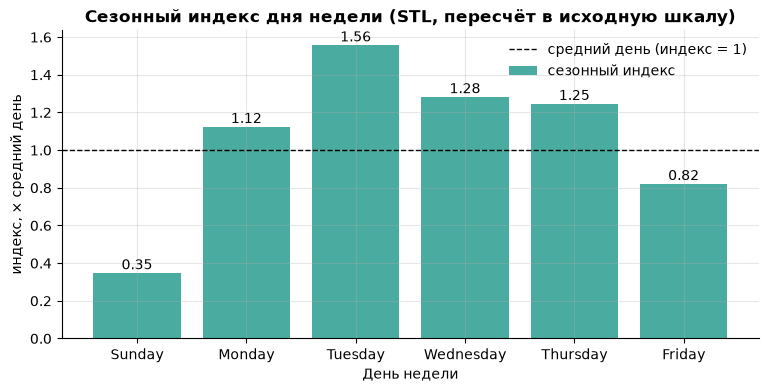

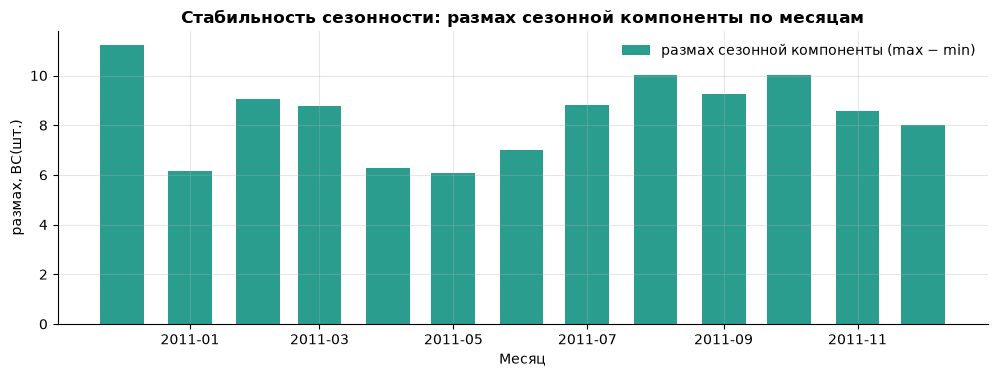

In [30]:
index = stl.seasonal_index()
fig = rp.plot_seasonal_profile(index, "Сезонный индекс дня недели (STL, пересчёт в исходную шкалу)", "индекс, × средний день"); plt.show()
amp = stl.seasonal_amplitude_over_time("MS")
fig, ax = plt.subplots(figsize=(12, 3.8))
ax.bar(amp.index, amp.values, width=20, color=rp.COLORS["green"], label="размах сезонной компоненты (max − min)")
ax.set(title="Стабильность сезонности: размах сезонной компоненты по месяцам", xlabel="Месяц", ylabel="размах, BC(шт.)")
ax.legend(loc="upper right"); plt.show()

Сезонный индекс получен пересчётом сезонной компоненты в штуки при среднем уровне тренда: **воскресенье ≈ 0.35** от «среднего» дня, **вторник ≈ 1.56**, среда ≈ 1.28, четверг ≈ 1.25, понедельник ≈ 1.12, пятница ≈ 0.82. Это совпадает с эмпирическим профилем медиан из п. 3.4. Размах сезонной компоненты колеблется по месяцам примерно от 6 до 11 (в шкале BC): ниже в январе и апреле–июне, выше в декабре и августе–октябре. Монотонного роста или затухания нет. **Форма недельного профиля стабильна, его выраженность умеренно меняется в течение года**, поэтому STL с гибкой сезонностью уместнее классической декомпозиции.

### 4.3 Статистическая проверка недельной сезонности

Чтобы вывод не опирался только на визуальное впечатление, `SeasonalityTester` проверяет четыре независимых признака:
1. ACF на лаге 6 выходит за 95% интервал Бартлетта;
2. критерий Краскела–Уоллиса по позиции в цикле (после удаления локального уровня);
3. **перестановочный тест** для $F_S$: детрендированный ряд перемешивается 199 раз, что разрушает любую периодичность, и наблюдаемая $F_S$ сравнивается с распределением при H0 «сезонности нет»;
4. пик периодограммы на периоде 6 или его гармониках (3, 2).

,признак,результат,подтверждает сезонность
0,ACF на лаге 6,0.175 (95% граница ±0.115),True
1,Краскел–Уоллис по позициям цикла,"H=53.2, p=3.05e-10, ε²=0.15",True
2,Перестановочный тест для F_S (STL),F_S=0.215; p=0.015 (H0: сезонности нет),True
3,Пик периодограммы (top-3 периода),"6.06, 3.00, 12.84",True


Вердикт: сезонность периода 6 ПОДТВЕРЖДЕНА; сила: слабая/умеренная: значима, но шум доминирует (F_S = 0.215)


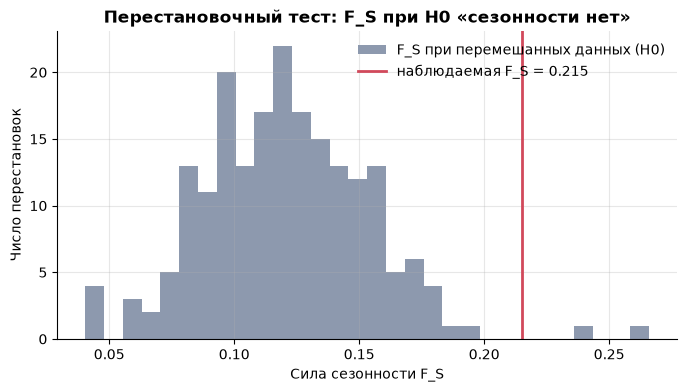

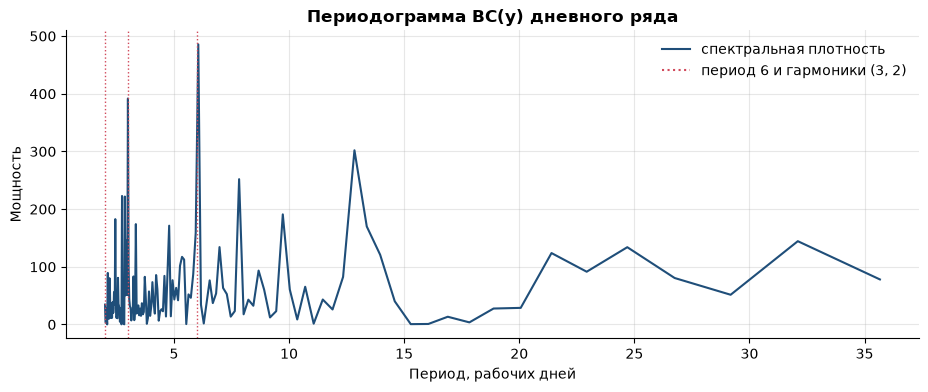

In [31]:
season_test = rt.SeasonalityTester(period=PERIOD, alpha=ALPHA, n_permutations=199, lam=LAM, random_state=42,
                                   stl_kwargs=STL_KW)
display(season_test.run(daily))
print(f"Вердикт: сезонность периода {PERIOD} {'ПОДТВЕРЖДЕНА' if season_test.verdict_ else 'НЕ подтверждена'}; "
      f"сила: {season_test.magnitude_} (F_S = {season_test.fs_:.3f})")
fig = rp.plot_permutation(season_test.null_, season_test.fs_, "Перестановочный тест: F_S при H0 «сезонности нет»"); plt.show()
fig = rp.plot_periodogram(BC(daily), f"Периодограмма BC(y) дневного ряда"); plt.show()

In [32]:
# Проверка чувствительности: тот же тест на ряду с ограниченными выбросами и в лог-шкале
for name, s, lam in [("ограниченные выбросы, BC", daily_capped, LAM), ("исходный, log(1+y)", daily, 0.0)]:
    t = rt.SeasonalityTester(period=PERIOD, n_permutations=199, lam=lam, random_state=42, stl_kwargs=STL_KW)
    r = t.run(s)
    print(f"{name:28s}: подтверждено {r['подтверждает сезонность'].sum()}/4, F_S = {t.fs_:.3f}, "
          f"перестановочный p = {t.p_perm_:.3f} → {'сезонность есть' if t.verdict_ else 'нет'}")

ограниченные выбросы, BC    : подтверждено 4/4, F_S = 0.240, перестановочный p = 0.015 → сезонность есть


исходный, log(1+y)          : подтверждено 4/4, F_S = 0.194, перестановочный p = 0.015 → сезонность есть


Все четыре признака согласованы: ACF(6) ≈ 0.175 при границе ±0.115; Краскел–Уоллис p ≈ 3·10⁻¹⁰ (ε² ≈ 0.15); перестановочный p ≈ 0.015 (лишь 2 из 199 перестановок дали $F_S$ не ниже наблюдаемой); на периодограмме доминируют периоды **6.06 и 3.0**, то есть основная частота недели и её вторая гармоника. Тот же результат получается на ряду с ограниченными выбросами и в лог-шкале.

**Вывод о сезонности дневного ряда:** присутствует **статистически значимая недельная сезонность с периодом 6 рабочих дней** (Вс–Пт): провал в воскресенье и пик во вторник–четверг. По силе она **слабая–умеренная** ($F_S \approx 0.22$), поскольку шум от крупных заказов доминирует.

### 4.4 Недельный и месячный ряды

Годовая сезонность здесь не идентифицируема (п. 4.1), поэтому ряды раскладываются на **тренд + остаток**. Тренд оценивается центрированным скользящим средним, а остаток проверяется на внутригодовую периодичность.

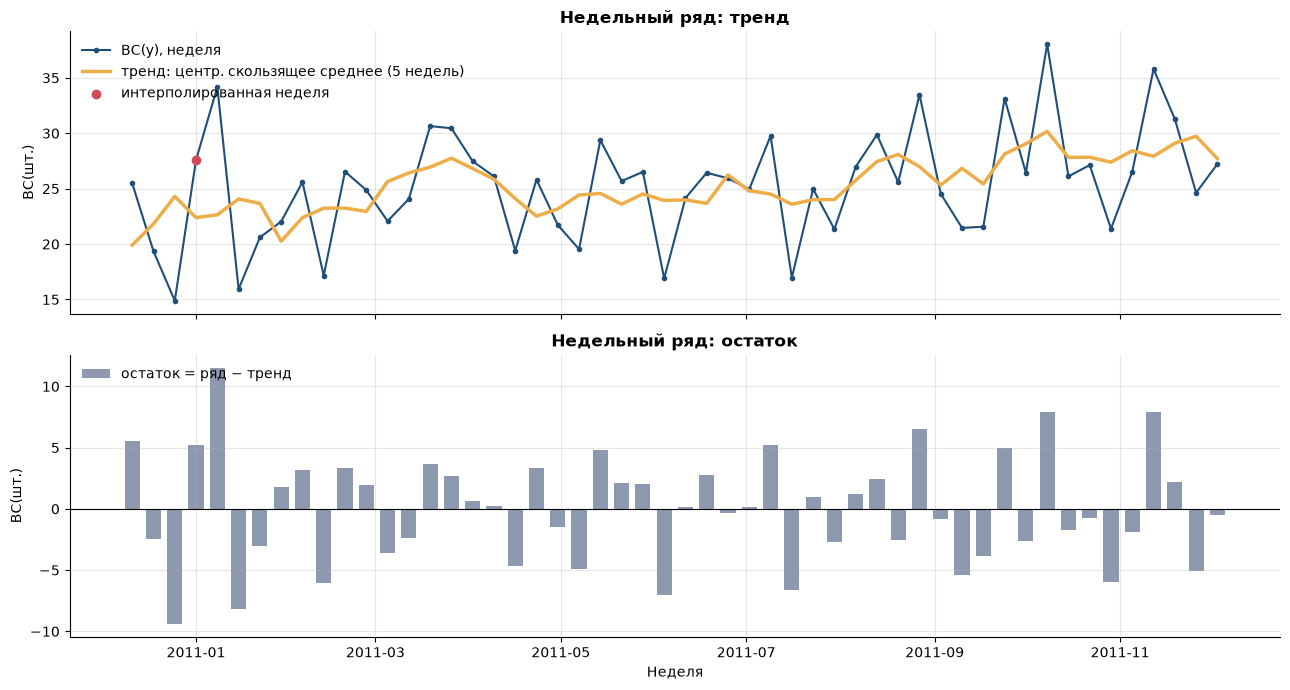

,frequency,period (steps),power,"share of power, %"
0,0.154,6.500,4.183,19.273
1,0.269,3.714,3.725,17.162
2,0.462,2.167,2.381,10.967


Недельный ряд, кандидат-период 4 недель: признаков подтверждено 0/4 → нет сезонности


Недельный ряд, кандидат-период 13 недель: признаков подтверждено 1/4 → нет сезонности


In [33]:
w_bc = BC(weekly_a)
w_trend = w_bc.rolling(5, center=True, min_periods=3).mean()
w_resid = w_bc - w_trend
fig, axes = plt.subplots(2, 1, figsize=(13, 7), sharex=True)
axes[0].plot(w_bc.index, w_bc, "o-", ms=3, color=rp.COLORS["main"], label="BC(y), неделя")
axes[0].plot(w_trend.index, w_trend, color=rp.COLORS["trend"], lw=2.5, label="тренд: центр. скользящее среднее (5 недель)")
axes[0].scatter(imputed_weeks, w_bc[imputed_weeks], color=rp.COLORS["accent"], zorder=4, label="интерполированная неделя")
axes[0].set(title="Недельный ряд: тренд", ylabel="BC(шт.)"); axes[0].legend(loc="upper left")
axes[1].bar(w_resid.index, w_resid, width=5, color=rp.COLORS["muted"], label="остаток = ряд − тренд")
axes[1].axhline(0, color="k", lw=0.8)
axes[1].set(title="Недельный ряд: остаток", xlabel="Неделя", ylabel="BC(шт.)"); axes[1].legend(loc="upper left")
fig.tight_layout(); plt.show()

display(rt.periodogram_peaks(w_bc, top=3))
for m in (4, 13):
    t = rt.SeasonalityTester(period=m, n_permutations=199, lam=LAM, random_state=42)
    res = t.run(weekly_a)
    print(f"Недельный ряд, кандидат-период {m} недель: признаков подтверждено "
          f"{res['подтверждает сезонность'].sum()}/4 → {'есть' if t.verdict_ else 'нет'} сезонности")

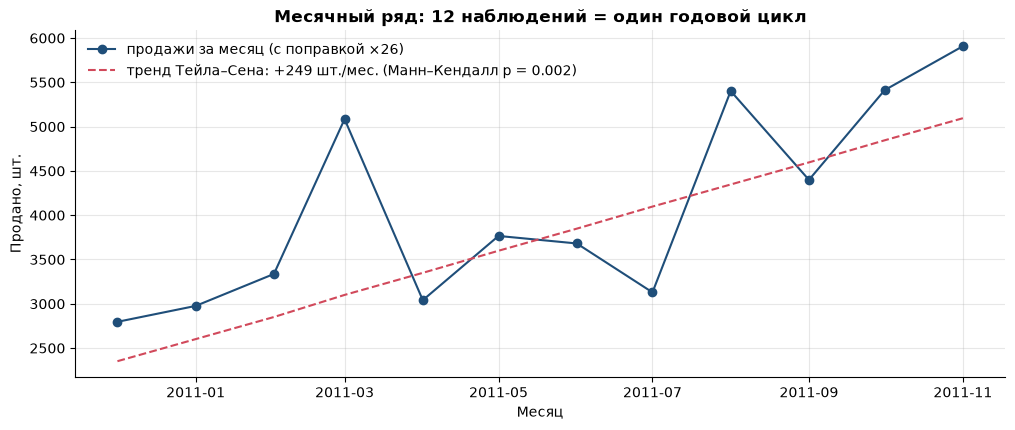

In [34]:
from scipy import stats as sps
x = np.arange(len(monthly_adj))
slope, intercept = sps.theilslopes(monthly_adj.values, x)[:2]
mk_m = rt.mann_kendall(monthly_adj)
fig, ax = plt.subplots(figsize=(12, 4.5))
ax.plot(monthly_adj.index, monthly_adj, "o-", color=rp.COLORS["main"], label="продажи за месяц (с поправкой ×26)")
ax.plot(monthly_adj.index, intercept + slope * x, "--", color=rp.COLORS["accent"],
        label=f"тренд Тейла–Сена: +{slope:,.0f} шт./мес. (Манн–Кендалл p = {mk_m['p-value']:.3f})")
ax.set(title="Месячный ряд: 12 наблюдений = один годовой цикл", xlabel="Месяц", ylabel=UNITS)
ax.legend(loc="upper left"); plt.show()

* **Недельный ряд.** Тренд такой же, как на дневном ряду: рост от зимы к осени. В остатке нет устойчивой периодичности: пики периодограммы разбросаны, ни один кандидат-период (4 недели ≈ месяц, 13 недель ≈ квартал) не подтверждается по всем признакам. **На недельной частоте сезонности не обнаружено**, годовую же проверить невозможно.
* **Месячный ряд.** 12 точек дают один цикл. Виден значимый восходящий тренд (Манн–Кендалл p ≈ 0.002, около +250 шт. в месяц) и рост в сентябре–ноябре. Сезонную декомпозицию проводить некорректно: при $n = m = 12$ сезонная компонента просто «копирует» данные. **Вывод о годовой сезонности не делается.**

<a id="step5"></a>
## Шаг 5. Стационарность

### 5.1 Методы

| тест | H0 | H1 | «стационарен», если |
|---|---|---|---|
| **ADF** (Дики–Фуллер, расширенный; лаги по AIC) | единичный корень | стационарность | p < 0.05 |
| **KPSS** (Квятковский–Филлипс–Шмидт–Шин) | стационарность (уровня `c` или вокруг тренда `ct`) | единичный корень | p ≥ 0.05 |
| **Зивот–Эндрюс** | единичный корень | стационарность с одним структурным сдвигом | p < 0.05 |

ADF и KPSS используются **вместе**, потому что у них противоположные нулевые гипотезы:
* оба говорят «стационарен» → ряд стационарен;
* оба говорят «нестационарен» → ряд нестационарен;
* ADF отвергает единичный корень, а KPSS отвергает стационарность уровня → ряд, скорее всего, **трендово-стационарен** или содержит сдвиг уровня. Это проверяется спецификацией `ct` (константа + тренд) и тестом Зивота–Эндрюса.

Дополнительно проверяется постоянство среднего и дисперсии по 4 последовательным отрезкам ряда (Краскел–Уоллис, Левене). Для KPSS statsmodels даёт p-value только в диапазоне [0.01, 0.10], значения на границах означают «≤ 0.01» и «≥ 0.10».

### 5.2 Исходные ряды

In [35]:
tester_c = rt.StationarityTester(regression="c", alpha=ALPHA)
original = {
    "день, y": daily,
    "день, BC(y)": BC(daily),
    "неделя, y (с поправкой)": weekly_a,
    "неделя, BC(y)": BC(weekly_a),
    "месяц, y (с поправкой)": monthly_adj,
}
res_c = tester_c.run(original)
display(res_c)

,n,ADF stat,ADF p-value,ADF lags,KPSS stat,KPSS p-value,KPSS lags,вывод
"день, y",321,-12.395,0.000,1,0.733,0.011,3,"противоречие: ADF — стационарен, KPSS — нет → ..."
"день, BC(y)",321,-4.932,0.000,8,1.269,0.010,4,"противоречие: ADF — стационарен, KPSS — нет → ..."
"неделя, y (с поправкой)",52,-6.533,0.000,0,0.589,0.024,0,"противоречие: ADF — стационарен, KPSS — нет → ..."
"неделя, BC(y)",52,-6.503,0.000,0,0.637,0.019,0,"противоречие: ADF — стационарен, KPSS — нет → ..."
"месяц, y (с поправкой)",12,2.393,0.999,4,0.527,0.036,1,нестационарен (оба теста согласны)


In [36]:
tester_ct = rt.StationarityTester(regression="ct", alpha=ALPHA)
res_ct = tester_ct.run({k: v for k, v in original.items() if not k.startswith("месяц")})
display(res_ct)

za = pd.DataFrame([rt.zivot_andrews_test(BC(daily)), rt.zivot_andrews_test(BC(weekly_a))],
                  index=["день, BC(y)", "неделя, BC(y)"])
display(za)

,n,ADF stat,ADF p-value,ADF lags,KPSS stat,KPSS p-value,KPSS lags,вывод
"день, y",321,-12.864,0.000,1,0.039,0.100,0,стационарен (оба теста согласны)
"день, BC(y)",321,-7.069,0.000,7,0.066,0.100,0,стационарен (оба теста согласны)
"неделя, y (с поправкой)",52,-5.860,0.000,2,0.073,0.100,3,стационарен (оба теста согласны)
"неделя, BC(y)",52,-5.843,0.000,2,0.082,0.100,5,стационарен (оба теста согласны)


,test,statistic,p-value,lags,nobs,crit 5%,break
"день, BC(y)",Zivot–Andrews (c),-7.611,0.000,7,321,-4.811,2011-02-13
"неделя, BC(y)",Zivot–Andrews (c),-6.653,0.000,2,52,-4.811,2011-04-23


In [37]:
rm = rt.rolling_moments_test(BC(daily), n_splits=4)
display(rm)
print(f"Краскел–Уоллис (равенство уровня по 4 отрезкам): p = {rm.attrs['kruskal_p']:.4f}")
print(f"Левене (равенство дисперсий по 4 отрезкам):      p = {rm.attrs['levene_p']:.4f}")

,part,mean,std
0,1,8.935,5.483
1,2,10.963,5.203
2,3,11.659,4.853
3,4,12.410,5.613


Краскел–Уоллис (равенство уровня по 4 отрезкам): p = 0.0003
Левене (равенство дисперсий по 4 отрезкам):      p = 0.8819


**Интерпретация для исходных рядов.**
* **Дневной ряд** ($y$ и $BC(y)$). ADF (`c`) уверенно отвергает единичный корень (p < 0.001), а KPSS (`c`) отвергает стационарность уровня (p ≤ 0.01). Противоречие разрешается, если добавить в обе спецификации линейный тренд: с `ct` **ADF отвергает единичный корень, а KPSS стационарность не отвергает (p ≥ 0.10)**. Тест Зивота–Эндрюса тоже отвергает единичный корень даже при допущении сдвига уровня. Значит, ряд **трендово-стационарен**: нестационарность создаётся детерминированным трендом, а не стохастическим (единичным корнем). Это согласуется со значимым трендом Манна–Кендалла и с тем, что средний уровень различается между четвертями ряда (Краскел–Уоллис p < 0.001), тогда как дисперсия в шкале BC по отрезкам однородна (Левене p ≈ 0.9).
* **Недельный ряд**: та же картина (ADF `c` отвергает единичный корень, KPSS `c` отвергает стационарность уровня, с `ct` оба указывают на стационарность), то есть ряд тоже трендово-стационарен.
* **Месячный ряд**: формально оба теста говорят «нестационарен», но при **n = 12** ADF с 4 лагами оценивает ~7 параметров по 12 точкам. Мощность обоих тестов при таком n ничтожна, результат **ненадёжен** и для выводов не используется. О нестационарности месячного ряда надёжнее судить по значимому тренду Манна–Кендалла.

**Вывод:** исходный ряд **нестационарен по среднему** (детерминированный восходящий тренд), единичного корня нет, дисперсия зависит от уровня (п. 3.3). Нужны преобразования: **Бокс–Кокс** для стабилизации дисперсии и **удаление тренда**.

### 5.3 Проверка устойчивости выводов

In [38]:
robust = {
    "только рабочие дни, без интерполяции, BC": BC(daily_trading),
    "с ограниченными выбросами, BC": BC(daily_capped),
    "log(1+y) вместо BC": np.log1p(daily),
}
display(pd.concat({"c": tester_c.run(robust), "ct": tester_ct.run(robust)}))

n ADF stat ADF p-value ADF lags KPSS stat KPSS p-value KPSS lags                                              вывод
c  только рабочие дни, без интерполяции, BC  305   -5.191       0.000        8     1.002        0.010         1  противоречие: ADF — стационарен, KPSS — нет → ...
   с ограниченными выбросами, BC             321   -5.334       0.000        5     1.425        0.010         5  противоречие: ADF — стационарен, KPSS — нет → ...
   log(1+y) вместо BC                        321   -5.588       0.000        5     1.557        0.010         5  противоречие: ADF — стационарен, KPSS — нет → ...
ct только рабочие дни, без интерполяции, BC  305   -7.388       0.000        7     0.038        0.100         4                   стационарен (оба теста согласны)
   с ограниченными выбросами, BC             321   -6.618       0.000        7     0.095        0.100         1                   стационарен (оба теста согласны)
   log(1+y) вместо BC                        321  -10.182       0.000        3     0.107        0.100         1                   стационарен (оба теста согласны)

Выводы не меняются ни на ряду **без интерполяции праздников** (только фактические рабочие дни), ни на ряду **с ограниченными выбросами**, ни при **логарифме** вместо BC: с `c` наблюдается то же противоречие (ADF отвергает единичный корень, KPSS отвергает стационарность уровня), с `ct` оба теста указывают на стационарность. Значит, интерполяция 16 праздничных дней, выбросы и выбор λ на вывод о стационарности не влияют.

### 5.4 Преобразования к стационарному виду

Сравниваются кандидаты (все в шкале BC):
1. `BC → Δ`: первая разность, стандартный способ убрать тренд или единичный корень;
2. `BC → Δ6`: сезонная разность, убирает и недельную сезонность, и уровень;
3. `BC → −лин.тренд`: вычитание линейного тренда МНК, «правильное» преобразование для трендово-стационарного ряда;
4. для сравнения `log1p → −лин.тренд`.

Кроме тестов проверяется **переразностирование**. Если ряд трендово-стационарен, разность вносит необратимую MA-компоненту: ACF(1) → −0.5, а дисперсия **растёт**.

In [39]:
transformers = {
    "BC → Δ": rt.SeriesTransformer([("boxcox", LAM), ("diff", 1)]),
    "BC → Δ6": rt.SeriesTransformer([("boxcox", LAM), ("diff", PERIOD)]),
    "BC → −лин.тренд": rt.SeriesTransformer([("boxcox", LAM), ("detrend",)]),
}
transformed = {name: tr.fit_transform(daily) for name, tr in transformers.items()}
log_detr = rt.SeriesTransformer([("log1p",), ("detrend",)]).fit_transform(daily)

display(tester_c.run({**transformed, "log1p → −лин.тренд": log_detr}))
display(rt.overdifferencing_check(BC(daily), transformed))

moments = pd.DataFrame({name: {"KW p (уровень по 4 отрезкам)": rt.rolling_moments_test(s).attrs["kruskal_p"],
                               "Levene p (дисперсия по 4 отрезкам)": rt.rolling_moments_test(s).attrs["levene_p"]}
                        for name, s in {**transformed, "log1p → −лин.тренд": log_detr}.items()}).T
display(moments)

,n,ADF stat,ADF p-value,ADF lags,KPSS stat,KPSS p-value,KPSS lags,вывод
BC → Δ,320,-7.410,0.000,15,0.057,0.100,18,стационарен (оба теста согласны)
BC → Δ6,315,-7.981,0.000,11,0.018,0.100,4,стационарен (оба теста согласны)
BC → −лин.тренд,321,-7.067,0.000,7,0.066,0.100,0,стационарен (оба теста согласны)
log1p → −лин.тренд,321,-10.197,0.000,3,0.107,0.100,1,стационарен (оба теста согласны)


,ACF(1),дисперсия,дисперсия / дисперсия исходного
BC → Δ,-0.365,46.864,1.590
BC → Δ6,0.207,48.653,1.651
BC → −лин.тренд,0.153,28.007,0.950


,KW p (уровень по 4 отрезкам),Levene p (дисперсия по 4 отрезкам)
BC → Δ,0.979,0.776
BC → Δ6,0.994,0.901
BC → −лин.тренд,0.548,0.908
log1p → −лин.тренд,0.416,0.052


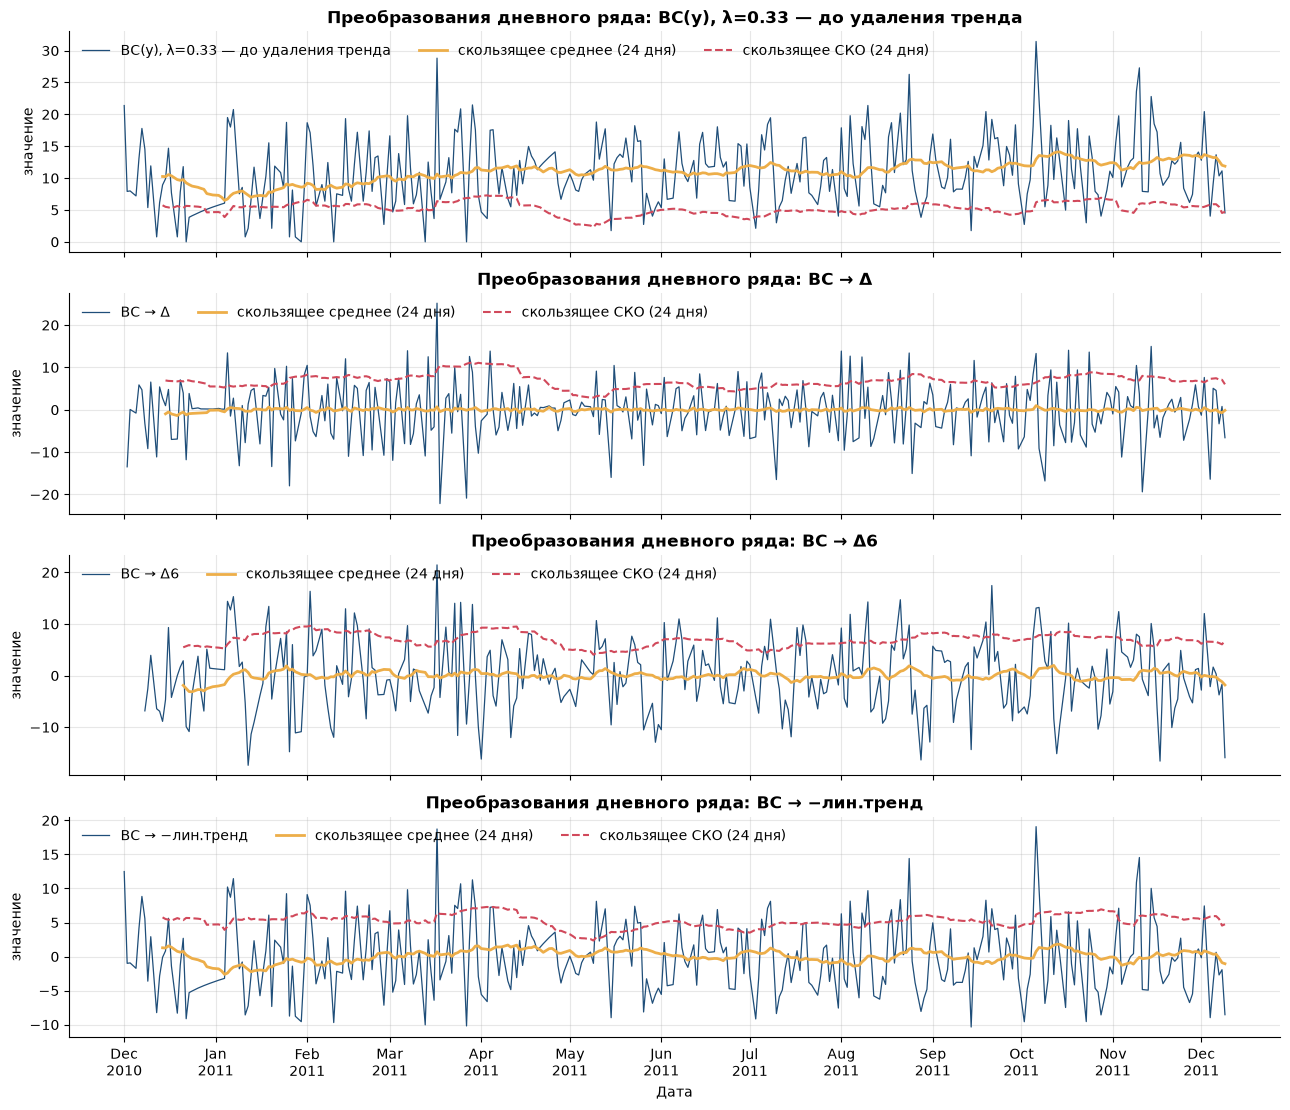

In [40]:
fig = rp.plot_transformations({f"BC(y), λ={LAM} — до удаления тренда": BC(daily), **transformed},
                              "Преобразования дневного ряда"); plt.show()

**Сравнение преобразований.**
* Все кандидаты проходят ADF и KPSS (`c`), то есть стационарны.
* Но у `BC → Δ` **ACF(1) ≈ −0.37, а дисперсия выросла в 1.6 раза** по сравнению с BC(y). Это классические признаки **переразностирования**, ожидаемые для трендово-стационарного ряда. `Δ6` так же увеличивает дисперсию в 1.65 раза и «съедает» 6 наблюдений.
* `BC → −лин.тренд` стационарен по обоим тестам, **ACF(1) ≈ 0.15, дисперсия не выросла** (0.95 от исходной), средний уровень и дисперсия однородны по отрезкам ряда (KW p ≈ 0.55, Левене p ≈ 0.9).
* `log1p → −лин.тренд` тоже проходит тесты, но дисперсия по отрезкам у него однородна заметно хуже (Левене p ≈ 0.05), это та же перекоррекция логарифма.

**Выбранное преобразование: $z_t = BC_{\lambda=0.33}(y_t) - (\hat a + \hat b\,t)$**, Бокс–Кокс плюс удаление линейного тренда.
* Бокс–Кокс обоснован зависимостью разброса от уровня (п. 3.3.1).
* Удаление детерминированного тренда обосновано тем, что ряд трендово-стационарен (п. 5.2). Разность здесь избыточна.

Недельная сезонность остаётся в $z_t$ как детерминированная периодическая составляющая. Модель с сезонными членами (SARIMA, дамми дней недели, Фурье-признаки) учтёт её явно. Если модель сезонность не поддерживает, к выбранному преобразованию добавляется удаление сезонной компоненты STL. Ниже показан этот вариант и обратимость преобразования.

,n,ADF stat,ADF p-value,ADF lags,KPSS stat,KPSS p-value,KPSS lags,вывод
z = BC − тренд,321,-7.067,0.000,7,0.066,0.100,0,стационарен (оба теста согласны)
z − сезонность STL,321,-5.634,0.000,17,0.063,0.100,4,стационарен (оба теста согласны)
остаток STL,321,-6.344,0.000,17,0.037,0.100,2,стационарен (оба теста согласны)


,lb_stat,lb_pvalue
лаг,,
6,18.387,0.005
12,27.221,0.007
24,52.396,0.001


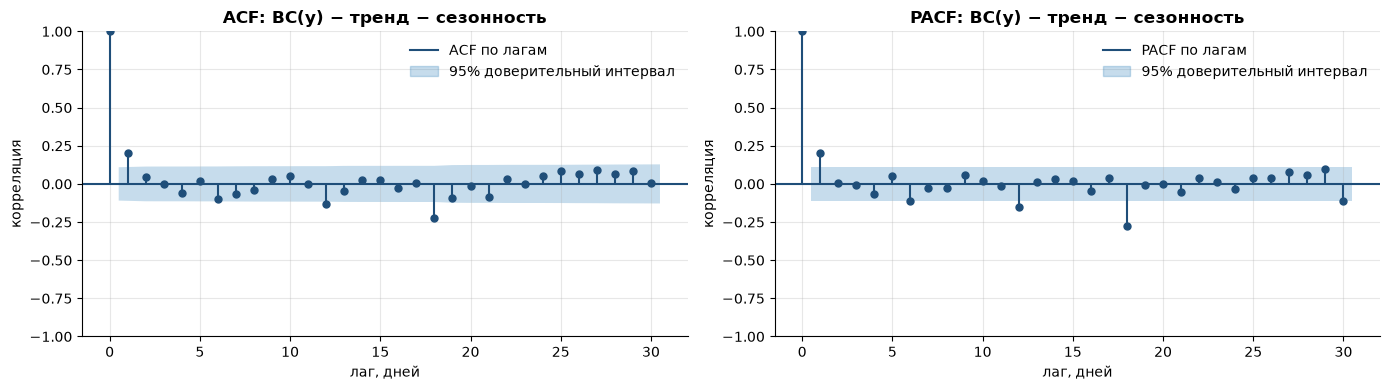

Обратное преобразование восстанавливает исходный ряд: True


In [41]:
chosen = transformers["BC → −лин.тренд"]
z = transformed["BC → −лин.тренд"]
z_sa = z - stl.result_["seasonal"]                       # дополнительно без недельной сезонности
final = {"z = BC − тренд": z, "z − сезонность STL": z_sa, "остаток STL": stl.result_["resid"]}
display(tester_c.run(final))
display(rt.ljung_box(z_sa, lags=[6, 12, 24]).rename_axis("лаг"))

fig = rp.plot_acf_pacf(z_sa, lags=30, title="BC(y) − тренд − сезонность"); plt.show()

restored = chosen.inverse_transform(z)
print("Обратное преобразование восстанавливает исходный ряд:", np.allclose(restored.values, daily.values))

Ряд $z_t$ без сезонности стационарен по ADF и KPSS. Положительные «зубцы» ACF на лагах, кратных 6, исчезли. Остались ACF(1) ≈ 0.2 (краткосрочная зависимость соседних дней) и отдельные небольшие отрицательные значения на лагах 12 и 18. Последние означают, что гибкая сезонная компонента STL слегка «перевычитает» сезонность, поэтому в модели её лучше учитывать явно (сезонные члены или дамми дней недели), а не только вычитанием. Тест Льюнга–Бокса отвергает «белый шум» (p < 0.05). Это нормально: стационарность не означает отсутствия автокорреляции, и оставшуюся зависимость будет описывать ARMA-часть модели. `SeriesTransformer.inverse_transform` точно восстанавливает исходный ряд, поэтому прогнозы, построенные на $z_t$, можно вернуть в штуки.

### 5.5 Недельный ряд

In [42]:
w_transformers = {
    "BC → Δ": rt.SeriesTransformer([("boxcox", LAM), ("diff", 1)]),
    "BC → −лин.тренд": rt.SeriesTransformer([("boxcox", LAM), ("detrend",)]),
}
w_transformed = {name: tr.fit_transform(weekly_a) for name, tr in w_transformers.items()}
display(tester_c.run(w_transformed))
display(rt.overdifferencing_check(BC(weekly_a), w_transformed))

,n,ADF stat,ADF p-value,ADF lags,KPSS stat,KPSS p-value,KPSS lags,вывод
BC → Δ,51,-3.449,0.009,9,0.263,0.100,27,стационарен (оба теста согласны)
BC → −лин.тренд,52,-5.924,0.000,2,0.082,0.100,5,стационарен (оба теста согласны)


,ACF(1),дисперсия,дисперсия / дисперсия исходного
BC → Δ,-0.436,47.565,1.890
BC → −лин.тренд,-0.058,22.132,0.880


На недельном ряду картина та же. После разности ACF(1) уходит к −0.5, а дисперсия почти удваивается (переразностирование). Вычитание линейного тренда в шкале BC даёт стационарный ряд без этих побочных эффектов. **Для недельного ряда тоже рекомендуется BC + удаление тренда.**

<a id="step7"></a>
## Итоги и выводы

| этап | результат |
|---|---|
| **Ряд** | `85099B` JUMBO BAG RED RETROSPOT, показатель — проданные штуки (без отмен, нулевых цен и дубликатов). Ряды: день (305 рабочих дней), неделя Вс–Сб (52 полные), месяц (12 полных). Неполные края исключены, недели и месяцы скорректированы на число рабочих дней. |
| **Пропуски** | Настоящих пропусков нет. 5 рабочих дней без продаж — истинные нули. 69 нерабочих дней (субботы, праздники) — не нули и не пропуски данных. Для STL и тестов 16 праздников на сетке Вс–Пт интерполированы, устойчивость выводов к этому проверена. |
| **Выбросы** | 18 дней (5.6%) по консенсусу IQR/Хампель/STL. Это реальные крупные оптовые заказы (до 1 200 шт.) нескольких постоянных клиентов и отложенный спрос после Рождества. Не удалены. Используются робастные методы, выводы проверены на ряду с ограниченными выбросами. |
| **Описательные характеристики** | Спрос erratic (ADI ≈ 1.02, CV² ≈ 1.36), сильная правая асимметрия (эксцесс ≈ 16). ~65% объёма дают строки больше 50 шт. Разброс растёт с уровнем. Бокс–Кокс с λ = 0.33 (робастный Герреро) убирает эту зависимость, а логарифм перекорректирует. |
| **Тренд** | Значимый восходящий тренд на всех частотах (Манн–Кендалл): уровень вырос примерно вдвое, с ~110 до ~220 шт./день. |
| **Сезонность** | Недельная, **период 6 рабочих дней** (Вс–Пт): воскресенье ≈ 0.35×, вторник ≈ 1.56×. Подтверждена ACF, Краскелом–Уоллисом, перестановочным тестом и периодограммой. Сила слабая–умеренная ($F_S$ ≈ 0.22). Годовую сезонность по одному году данных идентифицировать нельзя. |
| **Стационарность** | Исходный ряд нестационарен по среднему, но **трендово-стационарен**: ADF и Зивот–Эндрюс отвергают единичный корень, KPSS(`c`) отвергает стационарность уровня, KPSS(`ct`) нет. |
| **Преобразование** | Бокс–Кокс (λ = 0.33) → вычитание линейного тренда (+ удаление сезонности STL для моделей без сезонных членов). Первая разность тоже даёт формальную стационарность, но приводит к переразностированию (ACF(1) ≈ −0.37, дисперсия ×1.6). |

**Рекомендации для моделирования:** работать в шкале Бокса–Кокса с λ ≈ 0.33; тренд моделировать детерминированно (регрессор времени или `trend='t'` в SARIMAX), а не через `d = 1`; недельную сезонность учитывать периодом 6 или дамми дней недели; для краткосрочной автокорреляции использовать ARMA-часть; крупные оптовые заказы учитывать робастной функцией потерь или отдельной моделью. Для прогноза на несколько дней лучше дневной ряд, для планирования запасов — недельный, где шум крупных заказов усреднён.

In [43]:
# Сводка ключевых чисел, на которые опираются выводы (воспроизводится при перезапуске)
summary = pd.Series({
    "рабочих дней": len(daily_trading),
    "рабочих дней без продаж (истинные нули)": len(missing.no_sales_days()),
    "праздничных дней, интерполировано": len(imputed_days),
    "выбросов (консенсус)": int(detector.flags_["consensus"].sum()),
    "λ Бокса–Кокса (робастный Герреро)": LAM,
    "Манн–Кендалл p (день)": rt.mann_kendall(daily)["p-value"],
    "F_S недельной сезонности": season_test.fs_,
    "перестановочный p для F_S": season_test.p_perm_,
    "ADF p, BC(y), c": res_c.loc["день, BC(y)", "ADF p-value"],
    "KPSS p, BC(y), c": res_c.loc["день, BC(y)", "KPSS p-value"],
    "KPSS p, BC(y), ct": res_ct.loc["день, BC(y)", "KPSS p-value"],
    "KPSS p после BC − тренд": tester_c.run({"z": z}).loc["z", "KPSS p-value"],
})
display(summary.to_frame("значение"))

,значение
рабочих дней,305.000
рабочих дней без продаж (истинные нули),5.000
"праздничных дней, интерполировано",16.000
выбросов (консенсус),18.000
λ Бокса–Кокса (робастный Герреро),0.330
Манн–Кендалл p (день),0.000
F_S недельной сезонности,0.215
перестановочный p для F_S,0.015
"ADF p, BC(y), c",0.000
"KPSS p, BC(y), c",0.010
